# Smartphone & Smartwatch Activity Exploratory Data Analysis

This notebook explores the smartphone and smartwatch activity dataset
before building an activity-recognition model.

The goals of the EDA are to:

1. verify the integrity and coverage of the raw data,
2. understand the recording and sampling structure,
3. examine how sensor signals differ across activities and subjects,
4. identify preprocessing requirements,
5. determine an appropriate modeling and evaluation strategy.

The analysis is performed on the raw time-series measurements before windowing
or feature extraction.

## 1. Load, validate, and clean the raw data

### 1.1 Imports and constants

In [31]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
PROJECT_DIR = Path("..").resolve()
RAW_DIR = PROJECT_DIR / "raw"
CLEAN_DATA_PATH = PROJECT_DIR / "data_clean.parquet"

COLUMNS = [
    "subject_id",
    "activity_code",
    "timestamp",
    "x",
    "y",
    "z",
]

ACTIVITY_MAP = {
    "A": "Walking",
    "B": "Jogging",
    "C": "Stairs",
    "D": "Sitting",
    "E": "Standing",
    "F": "Typing",
    "G": "Brushing Teeth",
    "H": "Eating Soup",
    "I": "Eating Chips",
    "J": "Eating Pasta",
    "K": "Drinking from Cup",
    "L": "Eating Sandwich",
    "M": "Kicking Soccer Ball",
    "O": "Playing Catch",
    "P": "Dribbling Basketball",
    "Q": "Writing",
    "R": "Clapping",
    "S": "Folding Clothes",
}

EXPECTED_DEVICES = {"phone", "watch"}
EXPECTED_SENSORS = {"accel", "gyro"}

### 1.2 Load raw files

In [3]:
def load_sensor_file(path: Path) -> pd.DataFrame:
    df = pd.read_csv(
        path,
        header=None,
        names=COLUMNS,
    )

    # Raw files terminate the final value with ";"
    df["z"] = (
        df["z"]
        .astype(str)
        .str.rstrip(";")
        .astype("float32")
    )

    df["x"] = df["x"].astype("float32")
    df["y"] = df["y"].astype("float32")

    # Metadata encoded by the directory structure
    df["device"] = path.parts[-3]
    df["sensor"] = path.parts[-2]

    # Keep both raw code and readable activity name
    df["activity"] = df["activity_code"].map(ACTIVITY_MAP)

    return df

In [4]:
files = sorted(RAW_DIR.glob("*/*/data_*.txt"))

print(f"Sensor files found: {len(files)}")

Sensor files found: 204


In [5]:
raw = pd.concat(
    [load_sensor_file(path) for path in files],
    ignore_index=True,
)

print(f"Raw rows loaded: {len(raw):,}")

Raw rows loaded: 15,630,426


### 1.3 Inspect structure

In [ ]:
raw.head()

,subject_id,activity_code,timestamp,x,y,z,device,sensor,activity
0,1600,A,252207666810782,-0.364761,8.793503,1.055084,phone,accel,Walking
1,1600,A,252207717164786,-0.879730,9.768784,1.016998,phone,accel,Walking
2,1600,A,252207767518790,2.001495,11.109070,2.619156,phone,accel,Walking
3,1600,A,252207817872794,0.450623,12.651642,0.184555,phone,accel,Walking
4,1600,A,252207868226798,-2.164352,13.928436,-4.422485,phone,accel,Walking


In [7]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 15630426 entries, 0 to 15630425
Data columns (total 9 columns):
 #   Column         Dtype  
---  ------         -----  
 0   subject_id     int64  
 1   activity_code  str    
 2   timestamp      int64  
 3   x              float32
 4   y              float32
 5   z              float32
 6   device         str    
 7   sensor         str    
 8   activity       str    
dtypes: float32(3), int64(2), str(4)
memory usage: 894.4 MB


In [8]:
overview = pd.Series({
    "Rows": len(raw),
    "Columns": raw.shape[1],
    "Files": len(files),
    "Subjects": raw["subject_id"].nunique(),
    "Activity codes": raw["activity_code"].nunique(),
    "Devices": raw["device"].nunique(),
    "Sensors": raw["sensor"].nunique(),
})

overview.to_frame("value")

,value
Rows,15630426
Columns,9
Files,204
Subjects,51
Activity codes,18
Devices,2
Sensors,2


### 1.4 Validate labels/devices/sensors

In [9]:
observed_activity_codes = set(raw["activity_code"].dropna().unique())
expected_activity_codes = set(ACTIVITY_MAP)

unexpected_activity_codes = observed_activity_codes - expected_activity_codes
missing_activity_codes = expected_activity_codes - observed_activity_codes

print("Unexpected activity codes:", unexpected_activity_codes)
print("Missing activity codes:", missing_activity_codes)

Unexpected activity codes: set()
Missing activity codes: set()


In [10]:
print("Devices:", sorted(raw["device"].unique()))
print("Sensors:", sorted(raw["sensor"].unique()))

print(
    "Unexpected devices:",
    set(raw["device"].unique()) - EXPECTED_DEVICES,
)

print(
    "Unexpected sensors:",
    set(raw["sensor"].unique()) - EXPECTED_SENSORS,
)

Devices: ['phone', 'watch']
Sensors: ['accel', 'gyro']
Unexpected devices: set()
Unexpected sensors: set()


### 1.5 Check missing values

In [12]:
numeric_columns = ["timestamp", "x", "y", "z"]

quality_summary = pd.DataFrame({
    "missing": raw.isna().sum(),
})

quality_summary

,missing
subject_id,0
activity_code,0
timestamp,0
x,0
y,0
z,0
device,0
sensor,0
activity,0


### 1.6 Detect exact duplicates

In [15]:
duplicate_mask = raw.duplicated(keep="first")
duplicate_count = int(duplicate_mask.sum())

print(f"Exact duplicate rows: {duplicate_count:,}")
print(f"Duplicate percentage: {100 * duplicate_count / len(raw):.3f}%")

Exact duplicate rows: 263,696
Duplicate percentage: 1.687%


In [16]:
duplicate_summary = (
    raw.loc[duplicate_mask]
    .groupby(
        ["subject_id", "device", "sensor"],
        observed=True,
    )
    .size()
    .rename("duplicate_rows")
    .reset_index()
    .sort_values("duplicate_rows", ascending=False)
)

duplicate_summary

,subject_id,device,sensor,duplicate_rows
0,1629,phone,accel,69673
2,1629,watch,accel,64904
3,1629,watch,gyro,64869
1,1629,phone,gyro,64250


### 1.7 Create clean dataframe

In [17]:
data = (
    raw.loc[~duplicate_mask]
    .copy()
    .reset_index(drop=True)
)

SEQUENCE_KEYS = [
    "subject_id",
    "activity",
    "device",
    "sensor",
]

data = (
    data
    .sort_values(SEQUENCE_KEYS + ["timestamp"])
    .reset_index(drop=True)
)

In [18]:
categorical_columns = [
    "activity_code",
    "activity",
    "device",
    "sensor",
]

for column in categorical_columns:
    data[column] = data[column].astype("category")

### Verify Cleaning

In [19]:
print(f"Raw rows:   {len(raw):,}")
print(f"Clean rows: {len(data):,}")
print(f"Removed:    {len(raw) - len(data):,}")

print()
print("Remaining exact duplicates:", data.duplicated().sum())
print("Missing values:", data.isna().sum().sum())

Raw rows:   15,630,426
Clean rows: 15,366,730
Removed:    263,696

Remaining exact duplicates: 0
Missing values: 0


In [20]:
assert data.duplicated().sum() == 0
assert data["activity"].isna().sum() == 0
assert set(data["device"].unique()) <= EXPECTED_DEVICES
assert set(data["sensor"].unique()) <= EXPECTED_SENSORS

The dataset was checked for exact duplicate rows before continuing with the
analysis. An exact duplicate has the same subject, activity, timestamp,
device, sensor, and axis measurements.

We found 263,696 redundant duplicate rows. All of them belong to subject 1629,
whose measurements appear twice across every activity and sensor stream.
These duplicate copies were removed so that this subject does not receive
twice the weight of other subjects.

We also checked whether every subject performed every expected activity.
Four subject/activity pairs are completely missing:

- Subject 1616: Jogging
- Subject 1618: Playing Catch
- Subject 1642: Stairs
- Subject 1642: Typing

We will keep these subjects because only a small part of their data is missing.
The missing activities will remain absent rather than being filled or
artificially generated. During modeling, we should use subject-wise train/test
splits, report the number of observations supporting each activity, and ensure
that every evaluated activity is represented in both the training and test
sets. Analyses that require a complete subject-by-activity matrix should either
show these combinations as missing or exclude the affected subjects only for
that specific analysis.

### 1.8 Save clean dataset

In [ ]:
import pyarrow as pa
import pyarrow.parquet as pq

table = pa.Table.from_pandas(data, preserve_index=False)
pq.write_table(table, CLEAN_DATA_PATH)

### 1.9 Data-quality findings

The raw sensor files were loaded successfully and the expected activity,
device, and sensor categories were verified.

Exact duplicate measurements were detected and removed before any further
analysis. No artificial values were created for missing observations, and the
remaining rows were sorted chronologically within each subject/activity/sensor
recording.

The cleaned dataframe will be used for all subsequent EDA and is cached as
`data_clean.parquet`.

## 2. Dataset Overview and Coverage

Before examining timestamps or sensor signals, we first examine how the dataset
is distributed across subjects, activities, devices, and sensors.

A subject/activity pair represents one activity performed by one subject.
Ideally, each such pair contains four sensor streams:

- phone accelerometer
- phone gyroscope
- watch accelerometer
- watch gyroscope

This section checks whether all expected subject/activity pairs and sensor
streams are present.

Raw measurement counts are not used as the main measure of activity balance,
because different recordings may have different sampling frequencies.

### 2.1 Overview - Basic dataset inventory

In [38]:
subjects = sorted(data["subject_id"].unique())
activities = list(ACTIVITY_MAP.values())

overview = pd.Series(
    {
        "Rows": len(data),
        "Subjects": data["subject_id"].nunique(),
        "Activities": data["activity"].nunique(),
        "Devices": data["device"].nunique(),
        "Sensors": data["sensor"].nunique(),
    },
    name="value",
).to_frame()

overview

,value
Rows,15366730
Subjects,51
Activities,18
Devices,2
Sensors,2


### 2.2 Subject × activity coverage

Did every subject perform every activity?

In [39]:
subject_activity_counts = (
    data.groupby(
        ["subject_id", "activity"],
        observed=True,
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=subjects,
        columns=activities,
        fill_value=0,
    )
)

### 2.3 Missing subject/activity pairs

In [40]:
missing_activities = (
    subject_activity_counts.eq(0)
    .stack()
    .loc[lambda x: x]
    .rename("missing")
    .reset_index()
    .drop(columns="missing")
)

print(f"Expected subject/activity pairs: {len(subjects) * len(activities)}")
print(f"Missing subject/activity pairs: {len(missing_activities)}")

display(missing_activities)

Expected subject/activity pairs: 918
Missing subject/activity pairs: 4


,subject_id,activity
0,1616,Jogging
1,1618,Playing Catch
2,1642,Stairs
3,1642,Typing


Visualize subject/activity coverage. 


Here:

- black/dark = present

- white = missing

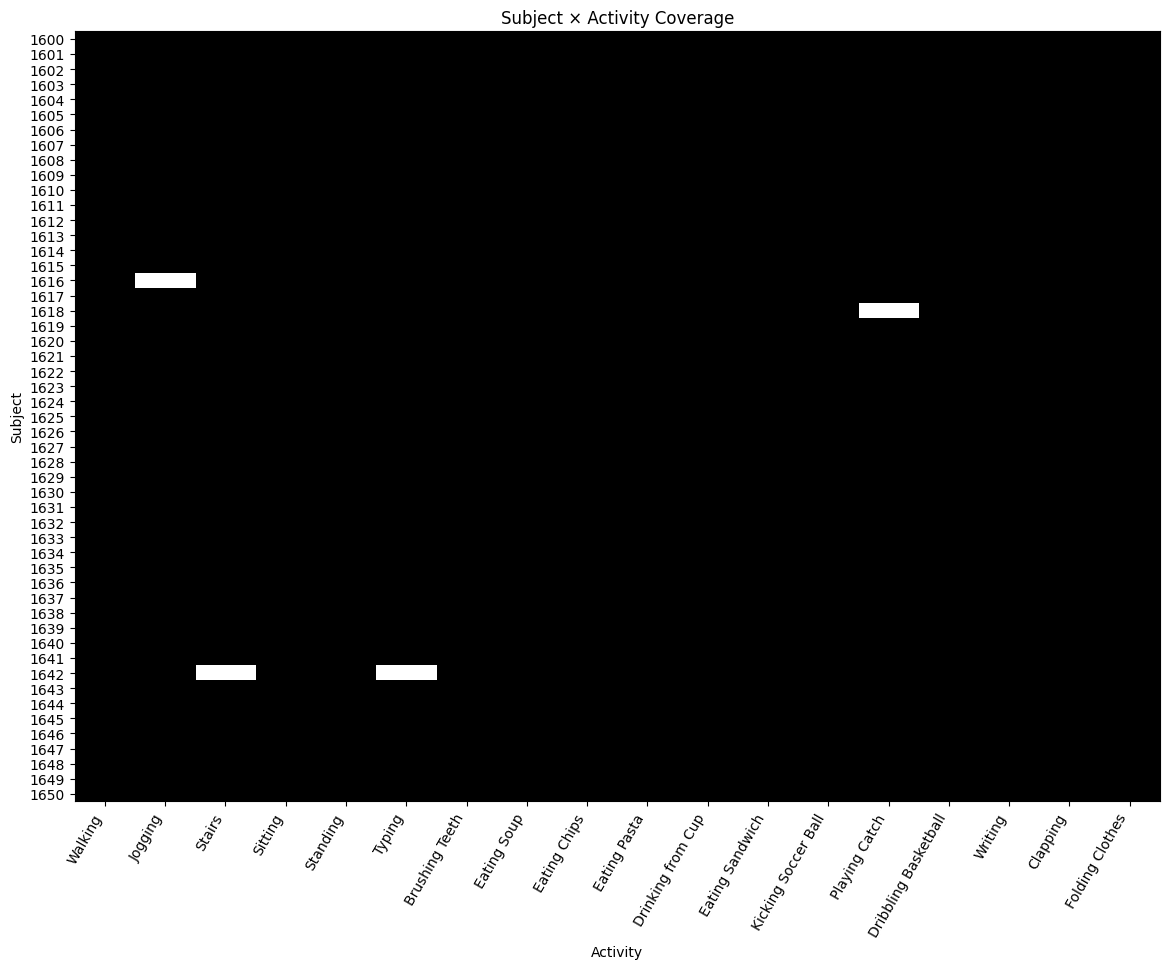

In [41]:
coverage_matrix = subject_activity_counts.gt(0).astype(int)

fig, ax = plt.subplots(figsize=(14, 10))

image = ax.imshow(
    coverage_matrix,
    aspect="auto",
    cmap="Greys",
    vmin=0,
    vmax=1,
)

ax.set_xticks(range(len(activities)))
ax.set_xticklabels(activities, rotation=60, ha="right")

ax.set_yticks(range(len(subjects)))
ax.set_yticklabels(subjects)

ax.set_xlabel("Activity")
ax.set_ylabel("Subject")
ax.set_title("Subject × Activity Coverage")

plt.show()

### 2.4 Activity coverage across subjects

In [42]:
activity_coverage = (
    data.groupby("activity", observed=True)["subject_id"]
    .nunique()
    .reindex(activities)
    .rename("subjects")
    .to_frame()
)

activity_coverage["coverage_pct"] = (
    100 * activity_coverage["subjects"] / len(subjects)
)

activity_coverage

,subjects,coverage_pct
activity,,
Walking,51,100.000000
Jogging,50,98.039216
Stairs,50,98.039216
Sitting,51,100.000000
Standing,51,100.000000
Typing,50,98.039216
Brushing Teeth,51,100.000000
Eating Soup,51,100.000000
Eating Chips,51,100.000000


### 2.5 sensor-stream coverage

In [49]:
devices = ["phone", "watch"]
sensors = ["accel", "gyro"]

expected_streams = pd.MultiIndex.from_product(
    [
        subjects,
        activities,
        devices,
        sensors,
    ],
    names=[
        "subject_id",
        "activity",
        "device",
        "sensor",
    ],
)

In [50]:
stream_counts = (
    data.groupby(
        [
            "subject_id",
            "activity",
            "device",
            "sensor",
        ],
        observed=True,
    )
    .size()
    .reindex(expected_streams, fill_value=0)
)

In [51]:
missing_streams = (
    stream_counts[stream_counts.eq(0)]
    .rename("rows")
    .reset_index()
    .drop(columns="rows")
)

2.6 Missing sensor streams

In [52]:
print(f"Expected sensor streams: {len(stream_counts)}")
print(f"Observed sensor streams: {(stream_counts > 0).sum()}")
print(f"Missing sensor streams:  {(stream_counts == 0).sum()}")

display(missing_streams)

Expected sensor streams: 3672
Observed sensor streams: 3637
Missing sensor streams:  35


,subject_id,activity,device,sensor
0,1607,Eating Pasta,phone,accel
1,1607,Eating Pasta,phone,gyro
2,1609,Jogging,phone,accel
3,1609,Jogging,phone,gyro
4,1616,Jogging,phone,accel
5,1616,Jogging,phone,gyro
6,1616,Jogging,watch,accel
7,1616,Jogging,watch,gyro
8,1616,Typing,phone,accel
9,1616,Typing,phone,gyro


### 2.6 Number of available streams per recording

In [54]:
stream_presence = (
    stream_counts.gt(0)
    .groupby(level=["subject_id", "activity"])
    .sum()
    .rename("available_streams")
    .reset_index()
)

stream_coverage_summary = (
    stream_presence["available_streams"]
    .value_counts()
    .sort_index()
    .rename_axis("available_streams")
    .rename("subject_activity_pairs")
    .to_frame()
)

stream_coverage_summary

,subject_activity_pairs
available_streams,
0,4
2,6
3,7
4,901


In [56]:
stream_type_coverage = (
    stream_counts.gt(0)
    .groupby(level=["device", "sensor"])
    .agg(["sum", "count"])
)

stream_type_coverage.columns = [
    "observed",
    "expected",
]

stream_type_coverage["missing"] = (
    stream_type_coverage["expected"]
    - stream_type_coverage["observed"]
)

stream_type_coverage["coverage_pct"] = (
    100
    * stream_type_coverage["observed"]
    / stream_type_coverage["expected"]
)

stream_type_coverage

observed  expected  missing  coverage_pct
device sensor                                           
phone  accel        910       918        8     99.128540
       gyro         908       918       10     98.910675
watch  accel        912       918        6     99.346405
       gyro         907       918       11     98.801743

### 2.7 Coverage findings

The cleaned dataset contains 51 subjects and all 18 expected activities.

Of the 918 possible subject/activity pairs, 914 are present. Four pairs are
completely missing:

- subject 1616 — Jogging
- subject 1618 — Playing Catch
- subject 1642 — Stairs
- subject 1642 — Typing

Consequently, Jogging, Stairs, Typing, and Playing Catch are each represented
by 50 subjects, while every other activity is represented by all 51 subjects.

Across the 918 subject/activity pairs and four possible device–sensor
combinations, 3,637 of 3,672 expected sensor streams are available
(approximately 99.0% coverage). The 35 missing streams consist of:

- 16 streams from the four completely missing subject/activity pairs,
- 12 streams from six pairs that contain only two streams,
- 7 streams from seven pairs that contain three streams.

Overall, 901 subject/activity pairs contain all four streams, six contain two,
seven contain three, four contain none, and no pair contains exactly one stream.

Missingness is similar between the phone and watch. Gyroscope streams are
missing somewhat more often than accelerometer streams, but every individual
device–sensor combination still has more than 98.8% coverage.

Coverage is therefore high but not perfectly complete. We will retain all
subjects and activities rather than manufacture missing streams. Later
preprocessing must explicitly define which streams are required when creating
single-sensor or multimodal windows.

## 3. Recording Duration, Timestamps, and Sampling Frequency

Each sensor stream is an irregularly stored time series rather than a set of
independent measurements.

This section examines:

- recording duration,
- timestamp consistency,
- inter-sample intervals,
- typical sampling frequency,
- effective sampling frequency,
- temporal gaps.

The unit of analysis is a single sensor stream defined by:

`subject × activity × device × sensor`

Understanding these properties is necessary before resampling, windowing, or
combining multiple sensors.

### 3.1 Per-stream timing summary

Each sensor stream is defined by a unique combination of:

`subject × activity × device × sensor`

For each stream, we summarize its duration, sampling intervals, and basic timing
properties. This creates a compact table that will be used throughout the rest
of the timing analysis.

In [70]:
STREAM_KEYS = [
    "subject_id",
    "activity",
    "device",
    "sensor",
]

NS_PER_SECOND = 1_000_000_000

timing = data[STREAM_KEYS].copy()

timing["delta_seconds"] = (
    data.groupby(STREAM_KEYS, observed=True)["timestamp"]
    .diff()
    / NS_PER_SECOND
)

timing["positive_delta"] = timing["delta_seconds"].where(
    timing["delta_seconds"] > 0
)

stream_summary = (
    data.groupby(STREAM_KEYS, observed=True)
    .agg(
        samples=("timestamp", "size"),
        start_timestamp=("timestamp", "min"),
        end_timestamp=("timestamp", "max"),
    )
    .reset_index()
)

interval_summary = (
    timing.groupby(STREAM_KEYS, observed=True)
    .agg(
        median_interval_seconds=("positive_delta", "median"),
        max_interval_seconds=("positive_delta", "max"),
        repeated_timestamps=("delta_seconds", lambda x: (x == 0).sum()),
    )
    .reset_index()
)

stream_summary = stream_summary.merge(
    interval_summary,
    on=STREAM_KEYS,
)

stream_summary["duration_seconds"] = (
    stream_summary["end_timestamp"]
    - stream_summary["start_timestamp"]
) / NS_PER_SECOND

stream_summary["typical_hz"] = (
    1 / stream_summary["median_interval_seconds"]
)

stream_summary["effective_hz"] = (
    (stream_summary["samples"] - 1)
    / stream_summary["duration_seconds"]
)

stream_summary["frequency_ratio"] = (
    stream_summary["effective_hz"]
    / stream_summary["typical_hz"]
)

stream_summary["max_gap_factor"] = (
    stream_summary["max_interval_seconds"]
    / stream_summary["median_interval_seconds"]
)

stream_summary.head()

,subject_id,activity,device,sensor,samples,start_timestamp,end_timestamp,median_interval_seconds,max_interval_seconds,repeated_timestamps,duration_seconds,typical_hz,effective_hz,frequency_ratio,max_gap_factor
0,1600,Brushing Teeth,phone,accel,3573,254171238814520,254351103296079,0.050354,0.050378,0,179.864482,19.859394,19.859396,1.000000,1.000475
1,1600,Brushing Teeth,phone,gyro,3569,254171440230536,254351103296079,0.050354,0.050378,0,179.663066,19.859394,19.859396,1.000000,1.000475
2,1600,Brushing Teeth,watch,accel,3604,92390268925882,92570102257932,0.049929,0.049936,0,179.833332,20.028360,20.035218,1.000342,1.000128
3,1600,Brushing Teeth,watch,gyro,3603,92390318425882,92570102257932,0.049929,0.049936,0,179.783832,20.028360,20.035172,1.000340,1.000128
4,1600,Clapping,phone,accel,3573,243826687535134,244006552032732,0.050354,0.050375,0,179.864498,19.859394,19.859394,1.000000,1.000410


The resulting `stream_summary` dataframe contains one row per sensor stream.

The main quantities used below are:

- `duration_seconds` — total recording duration
- `typical_hz` — local sampling frequency based on the median interval
- `effective_hz` — overall delivered sampling frequency across the recording
- `frequency_ratio` — agreement between typical and effective frequency
- `max_gap_factor` — size of the largest interval relative to the typical interval

### 3.2 Recording duration and sampling overview

We first examine whether recordings have similar durations and whether their
effective sampling rate matches their typical local sampling rate.

If the two sampling-rate measures differ substantially, this can indicate gaps
or interrupted sampling.

In [71]:
stream_summary[
    [
        "duration_seconds",
        "typical_hz",
        "effective_hz",
        "max_interval_seconds",
    ]
].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
)

,duration_seconds,typical_hz,effective_hz,max_interval_seconds
count,3637.000000,3637.000000,3637.000000,3637.000000
mean,179.938512,23.653059,23.477915,0.088295
std,4.022074,9.663046,8.394390,1.327691
min,179.491696,19.859394,11.135449,0.020136
1%,179.612730,19.859394,19.859391,0.020165
5%,179.663080,19.859394,19.859393,0.021014
50%,179.847337,20.029347,20.036135,0.049989
95%,180.006247,49.682035,49.625130,0.082292
99%,180.488888,49.761146,49.648488,0.286966
max,351.320124,100.489969,50.596453,56.655903


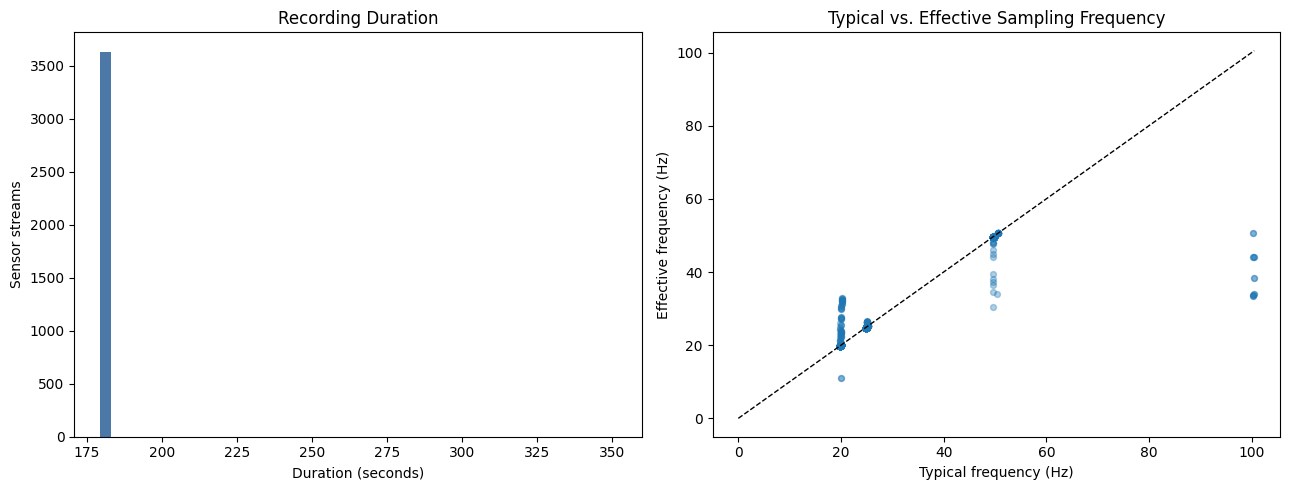

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    stream_summary["duration_seconds"],
    bins=50,
    color="#4C78A8",
)

axes[0].set(
    title="Recording Duration",
    xlabel="Duration (seconds)",
    ylabel="Sensor streams",
)

axes[1].scatter(
    stream_summary["typical_hz"],
    stream_summary["effective_hz"],
    alpha=0.35,
    s=18,
)

limit = max(
    stream_summary["typical_hz"].max(),
    stream_summary["effective_hz"].max(),
)

axes[1].plot(
    [0, limit],
    [0, limit],
    "--",
    color="black",
    linewidth=1,
)

axes[1].set(
    title="Typical vs. Effective Sampling Frequency",
    xlabel="Typical frequency (Hz)",
    ylabel="Effective frequency (Hz)",
)

plt.tight_layout()
plt.show()

The elapsed recording spans are highly concentrated around the intended
three-minute activity duration. The median span is 179.85 seconds, and the
1st–99th percentile range is approximately 179.61–180.49 seconds.

However, the maximum span is 351.32 seconds, indicating at least one substantial
timing anomaly. This outlier also stretches the histogram axis and makes the
variation around 180 seconds difficult to see.

Sampling cadence is not uniform. Most streams are close to 20 Hz, but additional
groups appear around 25 Hz and 50 Hz, with some streams having median intervals
corresponding to approximately 100 Hz. Points below the diagonal have a lower
effective frequency than local cadence, indicating gaps or burst-like sample
delivery.

### 3.3 Timing irregularities

Next, we inspect repeated timestamps and the streams with the largest mismatch
between typical and effective sampling frequency.

This helps identify recordings that may require special handling during
resampling or windowing.

In [73]:
print(
    "Repeated timestamps:",
    f"{stream_summary['repeated_timestamps'].sum():,}",
)

problematic_streams = (
    stream_summary[
        STREAM_KEYS
        + [
            "samples",
            "duration_seconds",
            "typical_hz",
            "effective_hz",
            "frequency_ratio",
            "max_interval_seconds",
            "max_gap_factor",
        ]
    ]
    .sort_values(
        ["frequency_ratio", "max_gap_factor"],
        ascending=[True, False],
    )
)

problematic_streams.head(15)

Repeated timestamps: 0


,subject_id,activity,device,sensor,samples,duration_seconds,typical_hz,effective_hz,frequency_ratio,max_interval_seconds,max_gap_factor
1872,1626,Drinking from Cup,watch,accel,6014,179.825137,100.197590,33.438039,0.333721,0.277470,27.801809
1873,1626,Drinking from Cup,watch,gyro,6013,179.775637,100.197590,33.441684,0.333757,0.277470,27.801809
660,1609,Drinking from Cup,watch,accel,6072,179.906120,100.280143,33.745378,0.336511,0.409026,41.017150
661,1609,Drinking from Cup,watch,gyro,6070,179.806844,100.280143,33.752887,0.336586,0.409026,41.017150
3027,1642,Eating Sandwich,watch,gyro,6134,179.749257,100.456030,34.119752,0.339649,0.314002,31.543420
3026,1642,Eating Sandwich,watch,accel,6141,179.936712,100.456030,34.123109,0.339682,0.314002,31.543420
597,1608,Eating Pasta,watch,gyro,6899,179.791880,100.489969,38.366583,0.381795,0.303741,30.522916
596,1608,Eating Pasta,watch,accel,6907,179.911106,100.489969,38.385624,0.381985,0.303741,30.522916
1548,1621,Sitting,watch,accel,7920,180.097825,100.345550,43.970548,0.438191,0.315190,31.627904
1549,1621,Sitting,watch,gyro,7918,179.838167,100.345550,44.022913,0.438713,0.315190,31.627904


No repeated timestamps were found.

The most irregular streams show two different timing problems. Several streams
have a very short median interval, corresponding to a local cadence near
100 Hz, but effective frequencies of only approximately 33–50 Hz. This suggests
bursty rather than continuously sustained high-rate sampling.

A more extreme example occurs for subject 1649 performing Kicking Soccer Ball:
the displayed stream has an elapsed span of approximately 351 seconds and a
maximum interval of 56.66 seconds. Such long gaps should eventually be treated
as recording boundaries rather than bridged by interpolation or windows.

#### Timing by device and sensor

We next compare median timing characteristics across the four device–sensor
combinations. This establishes whether the dominant sampling pattern differs
systematically by modality.

In [74]:
stream_summary.groupby(
    ["device", "sensor"],
    observed=True,
).agg(
    streams=("typical_hz", "size"),
    median_duration=("duration_seconds", "median"),
    median_typical_hz=("typical_hz", "median"),
    median_effective_hz=("effective_hz", "median"),
)

streams  median_duration  median_typical_hz  \
device sensor                                                
phone  accel       910       179.914847          20.005015   
       gyro        908       179.713440          19.859394   
watch  accel       912       179.865241          20.030031   
       gyro        907       179.767932          20.030029   

               median_effective_hz  
device sensor                       
phone  accel             20.014459  
       gyro              19.859397  
watch  accel             20.036930  
       gyro              20.036886

### 3.4 Sampling frequency across subjects

Sampling rate may vary because of the recording device or data-collection setup.

To check whether this variation is systematic, we compare the typical sampling
frequency of each sensor stream across subjects.

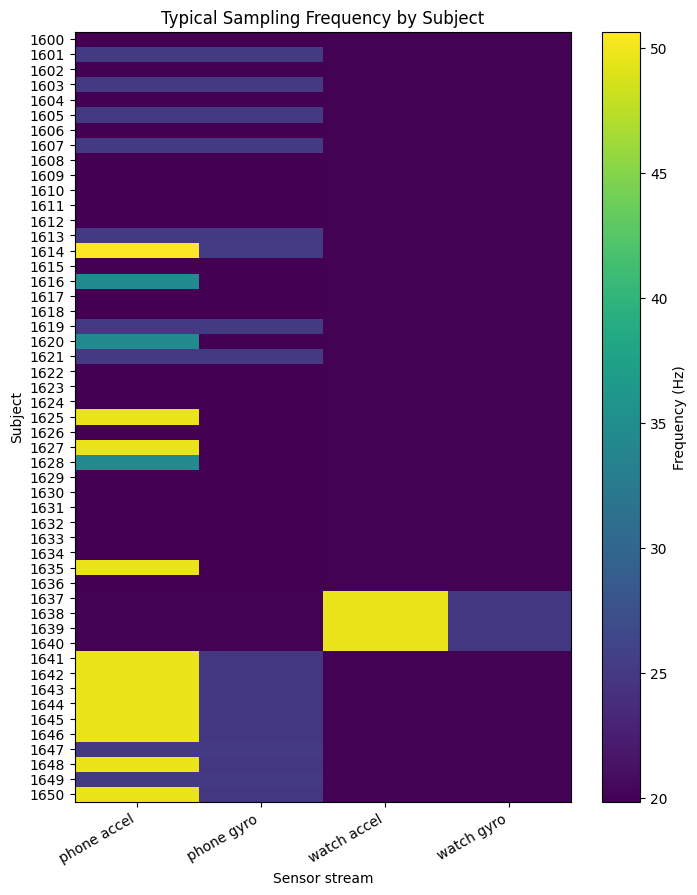

In [75]:
subject_frequency = (
    stream_summary
    .groupby(
        ["subject_id", "device", "sensor"],
        observed=True,
    )["typical_hz"]
    .median()
    .unstack(["device", "sensor"])
)

subject_frequency.columns = [
    f"{device} {sensor}"
    for device, sensor in subject_frequency.columns
]

fig, ax = plt.subplots(figsize=(8, 10))

image = ax.imshow(
    subject_frequency,
    aspect="auto",
    cmap="viridis",
)

ax.set_xticks(range(len(subject_frequency.columns)))
ax.set_xticklabels(
    subject_frequency.columns,
    rotation=30,
    ha="right",
)

ax.set_yticks(range(len(subject_frequency.index)))
ax.set_yticklabels(subject_frequency.index)

ax.set(
    title="Typical Sampling Frequency by Subject",
    xlabel="Sensor stream",
    ylabel="Subject",
)

fig.colorbar(image, ax=ax, label="Frequency (Hz)")

plt.show()

The heatmap shows structured subject- and device-specific differences rather
than random stream-to-stream variation. Most subjects have a local cadence near
20 Hz, while distinct subject groups show higher cadences for particular
devices or sensors.

This pattern suggests that multiple recording configurations or collection
cohorts are present. A single fixed samples-per-window assumption would
therefore represent different amounts of time across parts of the dataset.

### 3.5 Timing findings

Most sensor streams have an elapsed timestamp span close to the intended
three-minute activity duration. The median span is 179.85 seconds, with the
large majority tightly concentrated around 180 seconds. At least one stream has
a substantially longer span, reaching 351.32 seconds.

No repeated timestamps were detected. However, some streams contain pronounced
temporal gaps, including a maximum observed interval of 56.66 seconds.

The dataset does not have one uniform observed sampling cadence. Although the
median typical and effective frequencies are close to 20 Hz for all four
device–sensor combinations, the stream-level results contain additional groups
around 25 Hz and 50 Hz, together with burst-like local cadences near 100 Hz.
The subject heatmap shows that these differences are systematic across subjects
and devices.

Consequently, later preprocessing should use timestamps rather than assuming
that a fixed number of rows represents a fixed duration. Long gaps should be
treated as sequence boundaries, and any resampling strategy should be applied
within continuous stream segments rather than across interruptions.

## 4. Sensor Synchronization and Alignment

This section asks two separate questions:

1. Are the accelerometer and gyroscope synchronized within each device?
2. Can phone and watch timestamps be compared directly?

Android sensor timestamps use a monotonic device-relative clock. Accelerometer
and gyroscope timestamps from the same device can therefore be compared
directly. Phone and watch timestamps may have different clock origins, so a
large raw difference between them does not necessarily indicate that the
devices recorded at different real-world times.

The analysis must therefore distinguish within-device synchronization from
cross-device clock offset.

### 4.1 Construct the alignment table

A subject/activity pair may contain up to four streams:

- phone accelerometer
- phone gyroscope
- watch accelerometer
- watch gyroscope

Using the per-stream timing summary from Part 3, we place the start and end
timestamps of these streams into one row per subject/activity pair.

Within-device accelerometer–gyroscope offsets measure synchronization directly.
Phone–watch differences are initially calculated only to determine whether the
two devices appear to share a timestamp reference; they should not yet be
interpreted as recording misalignment.

In [76]:
alignment_long = stream_summary.copy()

alignment_long["stream"] = (
    alignment_long["device"].astype(str)
    + "_"
    + alignment_long["sensor"].astype(str)
)

stream_names = [
    "phone_accel",
    "phone_gyro",
    "watch_accel",
    "watch_gyro",
]

starts = (
    alignment_long
    .pivot(
        index=["subject_id", "activity"],
        columns="stream",
        values="start_timestamp",
    )
    .reindex(columns=stream_names)
)

ends = (
    alignment_long
    .pivot(
        index=["subject_id", "activity"],
        columns="stream",
        values="end_timestamp",
    )
    .reindex(columns=stream_names)
)

In [77]:
alignment_summary = pd.DataFrame(index=starts.index)

alignment_summary["available_streams"] = starts.notna().sum(axis=1)

# Accelerometer vs gyroscope alignment within each device
for device in ["phone", "watch"]:
    alignment_summary[f"{device}_start_offset_s"] = (
        starts[f"{device}_accel"]
        - starts[f"{device}_gyro"]
    ).abs() / NS_PER_SECOND

    alignment_summary[f"{device}_end_offset_s"] = (
        ends[f"{device}_accel"]
        - ends[f"{device}_gyro"]
    ).abs() / NS_PER_SECOND


# Approximate start/end of each device recording
phone_start = starts[["phone_accel", "phone_gyro"]].min(axis=1)
watch_start = starts[["watch_accel", "watch_gyro"]].min(axis=1)

phone_end = ends[["phone_accel", "phone_gyro"]].max(axis=1)
watch_end = ends[["watch_accel", "watch_gyro"]].max(axis=1)

alignment_summary["phone_watch_start_offset_s"] = (
    phone_start - watch_start
).abs() / NS_PER_SECOND

alignment_summary["phone_watch_end_offset_s"] = (
    phone_end - watch_end
).abs() / NS_PER_SECOND

alignment_summary = alignment_summary.reset_index()

alignment_summary.head()

,subject_id,activity,available_streams,phone_start_offset_s,phone_end_offset_s,watch_start_offset_s,watch_end_offset_s,phone_watch_start_offset_s,phone_watch_end_offset_s
0,1600,Brushing Teeth,4,0.201416,0.000000,0.049500,0.000000,161780.969889,161781.001038
1,1600,Clapping,4,0.201416,0.000000,0.000000,0.049929,161781.314556,161781.323537
2,1600,Dribbling Basketball,4,0.201416,0.000000,0.049500,0.049927,161780.938568,161780.996444
3,1600,Drinking from Cup,4,0.201416,0.000000,0.049587,0.049934,161781.307049,161781.270416
4,1600,Eating Chips,4,0.151062,0.050354,0.000000,0.049930,161781.374348,161781.341787


The alignment table contains one row per subject/activity pair.

The within-device columns compare streams that use the same device clock. In
the displayed rows, accelerometer and gyroscope start and end differences are
generally fractions of a second.

By contrast, the displayed phone–watch differences are approximately 161,781
seconds even though each activity recording lasts approximately 180 seconds.
This cannot represent a genuine activity-session delay. It indicates that the
phone and watch timestamps use different clock origins.

Therefore, raw phone–watch timestamp differences are clock offsets, not direct
measures of synchronization.

### 4.2 Within-device synchronization and cross-device clock offsets

We summarize the start and end differences between accelerometer and gyroscope
streams recorded by the same device.

We also inspect the raw phone–watch differences as a diagnostic of their
timestamp references. If these differences are much larger than the activity
duration and vary systematically by subject, the two devices cannot be assumed
to share a common time origin.

In [78]:
offset_columns = [
    "phone_start_offset_s",
    "phone_end_offset_s",
    "watch_start_offset_s",
    "watch_end_offset_s",
    "phone_watch_start_offset_s",
    "phone_watch_end_offset_s",
]

alignment_summary[
    offset_columns
].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
).T

,count,mean,std,min,50%,90%,95%,99%,max
phone_start_offset_s,908.0,1.145732,28.552826,0.000000,0.151062,0.374756,6.456604e-01,1.269345e+00,8.605536e+02
phone_end_offset_s,908.0,0.963067,28.562094,0.000000,0.000038,0.050354,5.035400e-02,5.035400e-02,8.606776e+02
watch_start_offset_s,907.0,0.051550,0.037144,0.000000,0.049500,0.049500,1.189332e-01,1.801117e-01,4.454090e-01
watch_end_offset_s,907.0,0.043944,0.018016,0.000000,0.049929,0.049987,4.999328e-02,4.999812e-02,2.101579e-01
phone_watch_start_offset_s,908.0,327687.664967,510764.955249,273.966729,161781.262132,900088.571719,1.631338e+06,2.068450e+06,2.068451e+06
phone_watch_end_offset_s,908.0,327686.904369,510766.017781,274.012916,161781.164232,900089.251345,1.631338e+06,2.068450e+06,2.068451e+06


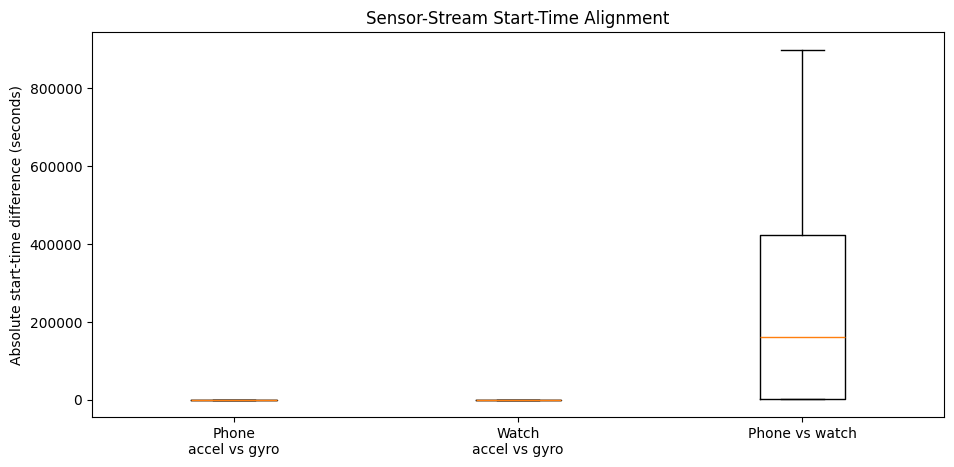

In [79]:
fig, ax = plt.subplots(figsize=(11, 5))

plot_columns = [
    "phone_start_offset_s",
    "watch_start_offset_s",
    "phone_watch_start_offset_s",
]

labels = [
    "Phone\naccel vs gyro",
    "Watch\naccel vs gyro",
    "Phone vs watch",
]

ax.boxplot(
    [
        alignment_summary[column].dropna()
        for column in plot_columns
    ],
    tick_labels=labels,
    showfliers=False,
)

ax.set(
    ylabel="Absolute start-time difference (seconds)",
    title="Sensor-Stream Start-Time Alignment",
)

plt.show()

In [80]:
alignment_summary[
    [
        "subject_id",
        "activity",
        "available_streams",
        "phone_watch_start_offset_s",
        "phone_watch_end_offset_s",
    ]
].sort_values(
    "phone_watch_start_offset_s",
    ascending=False,
).head(10)

,subject_id,activity,available_streams,phone_watch_start_offset_s,phone_watch_end_offset_s
908,1650,Sitting,4,2.068451e+06,2.068451e+06
911,1650,Typing,4,2.068451e+06,2.068451e+06
910,1650,Standing,4,2.068451e+06,2.068451e+06
902,1650,Eating Sandwich,4,2.068451e+06,2.068450e+06
904,1650,Folding Clothes,4,2.068451e+06,2.068450e+06
900,1650,Eating Chips,4,2.068451e+06,2.068450e+06
912,1650,Walking,4,2.068451e+06,2.068450e+06
913,1650,Writing,4,2.068450e+06,2.068450e+06
909,1650,Stairs,4,2.068450e+06,2.068450e+06
899,1650,Drinking from Cup,4,2.068450e+06,2.068450e+06


Within-device synchronization is generally close:

- the median phone accelerometer–gyroscope start difference is approximately
  0.15 seconds;
- the median phone end difference is effectively zero;
- the median watch start and end differences are approximately 0.05 seconds.

The upper percentiles are also small for most streams. However, the phone
results contain an extreme start/end difference of approximately 861 seconds,
which should be investigated separately rather than represented by the mean.

Raw phone–watch offsets are fundamentally different. They range from
approximately 274 seconds to more than 2 million seconds, with a median near
161,781 seconds. The largest offsets are concentrated in subject 1650, showing
that the differences are systematic and likely determined by device uptime or
clock origin.

The phone–watch values in the boxplot should therefore not be compared directly
with the within-device offsets. Their much larger scale also visually compresses
the meaningful phone and watch accelerometer–gyroscope distributions.

### 4.3 Raw cross-device overlap diagnostic

The following calculation tests what happens if all four raw timestamp ranges
are treated as though they use a shared clock.

Because the preceding results indicate different phone and watch timestamp
origins, this is a diagnostic check rather than a valid measurement of
real-world overlap. A zero overlap would show that raw timestamps cannot be
combined directly; it would not prove that the devices were not recording
simultaneously.

In [81]:
complete_mask = starts.notna().all(axis=1)

complete_starts = starts.loc[complete_mask]
complete_ends = ends.loc[complete_mask]

latest_start = complete_starts.max(axis=1)
earliest_start = complete_starts.min(axis=1)

earliest_end = complete_ends.min(axis=1)
latest_end = complete_ends.max(axis=1)

complete_alignment = pd.DataFrame({
    "start_spread_seconds": (
        latest_start - earliest_start
    ) / NS_PER_SECOND,

    "end_spread_seconds": (
        latest_end - earliest_end
    ) / NS_PER_SECOND,

    "overlap_seconds": (
        (earliest_end - latest_start) / NS_PER_SECOND
    ).clip(lower=0),

    "union_seconds": (
        latest_end - earliest_start
    ) / NS_PER_SECOND,
})

complete_alignment["overlap_ratio"] = (
    complete_alignment["overlap_seconds"]
    / complete_alignment["union_seconds"]
)

complete_alignment = complete_alignment.reset_index()

In [82]:
complete_alignment[
    [
        "start_spread_seconds",
        "end_spread_seconds",
        "overlap_seconds",
        "overlap_ratio",
    ]
].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
)

,start_spread_seconds,end_spread_seconds,overlap_seconds,overlap_ratio
count,9.010000e+02,9.010000e+02,901.0,901.0
mean,3.302171e+05,3.302171e+05,0.0,0.0
std,5.119367e+05,5.119372e+05,0.0,0.0
min,2.739905e+02,2.740129e+02,0.0,0.0
1%,2.777010e+02,2.777676e+02,0.0,0.0
5%,5.518170e+02,5.517640e+02,0.0,0.0
50%,1.617815e+05,1.617814e+05,0.0,0.0
95%,1.631338e+06,1.631338e+06,0.0,0.0
99%,2.068451e+06,2.068450e+06,0.0,0.0
max,2.068451e+06,2.068451e+06,0.0,0.0


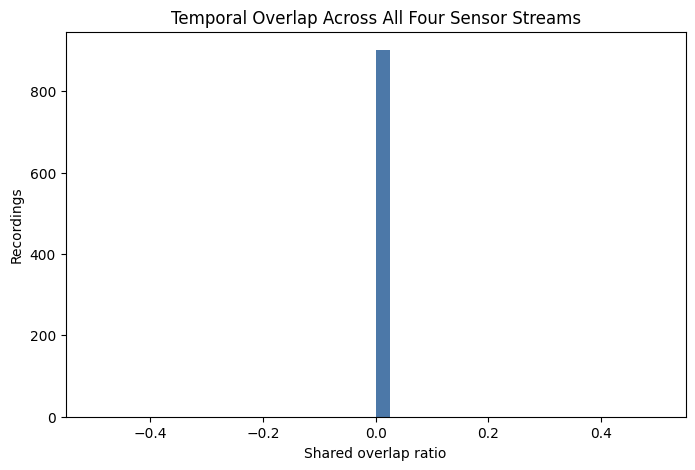

In [83]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    complete_alignment["overlap_ratio"],
    bins=40,
    color="#4C78A8",
)

ax.set(
    xlabel="Shared overlap ratio",
    ylabel="Recordings",
    title="Temporal Overlap Across All Four Sensor Streams",
)

plt.show()

All 901 subject/activity pairs containing four streams have a calculated raw
overlap of zero.

This is not evidence that the phone and watch recordings failed to overlap in
real time. It is an artifact of comparing timestamp ranges with different
device-specific origins. The start and end spreads are much larger than the
approximately three-minute activity duration, making the raw overlap calculation
invalid for cross-device synchronization.

Actual phone–watch overlap cannot be determined from these unadjusted timestamps.
Cross-device fusion will require a common relative time representation or an
estimated clock offset. Normalizing each stream to elapsed time since its own
start can align recording ranges approximately, but it does not by itself prove
sample-level synchronization; that may require signal-based lag analysis.

### 4.4 Synchronization findings

Accelerometer and gyroscope streams recorded by the same device are generally
well aligned, usually beginning and ending within a fraction of a second of one
another. A small number of extreme within-device offsets require separate
inspection.

Phone and watch raw timestamps do not share a directly comparable origin.
Consequently, their large timestamp differences and zero calculated raw overlap
must not be interpreted as genuine recording delays or missing simultaneous
coverage.

For later preprocessing:

- timestamps can be compared directly within a device;
- raw timestamps should not be used directly to merge phone and watch samples;
- each continuous stream should first be represented on a relative-time scale;
- both devices should be resampled to a common time grid before fusion;
- long gaps identified in Part 3 should remain sequence boundaries;
- any remaining phone–watch lag should be evaluated using the sensor signals,
  rather than inferred from raw clock values alone.

## 5. Sensor Distributions, Clipping, and Extreme Values

This section examines the scale and shape of the raw sensor measurements and
asks whether the most extreme values show evidence of sensor saturation.

Accelerometer and gyroscope values are analyzed separately for the phone and
watch because they have different physical units, measurement ranges, and
device-relative coordinate systems.

### 5.1 Sensor value ranges

Before comparing activities, we examine the numerical range of the raw
accelerometer and gyroscope measurements.

Phone and watch axes are analyzed separately because their coordinate systems
and sensor ranges may differ. At this stage, the goal is only to understand the
scale and distribution of the raw measurements.

In [85]:
AXES = ["x", "y", "z"]

value_summary = (
    data.groupby(
        ["device", "sensor"],
        observed=True,
    )[AXES]
    .describe(
        percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]
    )
)

value_summary

x                                                       \
                   count      mean       std        min       0.1%         1%   
device sensor                                                                   
phone  accel   4734730.0  0.163010  5.864268 -78.477608 -19.613300 -10.685758   
       gyro    3544385.0 -0.004225  0.845592 -24.770920  -5.998060  -2.880516   
watch  accel   3712142.0  0.364692  6.966630 -70.631523 -19.783737 -12.898462   
       gyro    3375473.0 -0.026837  1.570931 -34.917301 -10.351190  -5.212840   

                                                          ...          z  \
                    50%        99%      99.9%        max  ...      count   
device sensor                                             ...              
phone  accel   0.147278  12.176280  19.612701  78.477608  ...  4734730.0   
       gyro   -0.001007   2.786732   5.914308  23.529480  ...  3544385.0   
watch  accel  -0.418836  19.437775  19.645023  52.113232  ...  3712142.0   
       gyro    0.000539   4.780040   9.569265  34.905415  ...  3375473.0   

                                                                              \
                   mean       std        min       0.1%         1%       50%   
device sensor                                                                  
phone  accel   0.383880  5.107666 -78.477608 -17.486916  -9.641586  0.064117   
       gyro   -0.001592  0.659698 -34.984863  -5.156981  -2.209358 -0.001065   
watch  accel   1.868804  5.243045 -78.477608 -19.680937 -12.132617  1.822511   
       gyro    0.013932  1.412381 -34.548958  -8.922074  -4.780095  0.001032   

                                                
                     99%      99.9%        max  
device sensor                                   
phone  accel    9.915381  18.623895  69.081947  
       gyro     2.211799   4.953238  18.548330  
watch  accel   13.249090  19.644125  66.615074  
       gyro     4.438979   7.243908  18.418898  

[4 rows x 30 columns]

In [86]:
range_summary = (
    data.groupby(
        ["device", "sensor"],
        observed=True,
    )[AXES]
    .agg(["min", "median", "max"])
)

range_summary

x                               y                       \
                     min    median        max        min    median        max   
device sensor                                                                   
phone  accel  -78.477608  0.147278  78.477608 -78.477608 -2.175132  64.411659   
       gyro   -24.770920 -0.001007  23.529480 -34.978287 -0.000748  31.623199   
watch  accel  -70.631523 -0.418836  52.113232 -78.477608 -4.533571  35.601967   
       gyro   -34.917301  0.000539  34.905415 -34.900162  0.000861  34.069073   

                       z                       
                     min    median        max  
device sensor                                  
phone  accel  -78.477608  0.064117  69.081947  
       gyro   -34.984863 -0.001065  18.548330  
watch  accel  -78.477608  1.822511  66.615074  
       gyro   -34.548958  0.001032  18.418898

The central measurement ranges differ substantially between accelerometers and
gyroscopes.

Most accelerometer measurements fall within roughly ±20 m/s² at the
0.1st–99.9th percentiles, while the absolute extrema reach approximately
±78.48 m/s². Most gyroscope measurements are much closer to zero, but their
absolute extrema reach approximately ±35 rad/s.

The minima and maxima are therefore much farther from the central distributions
than the robust percentile bounds. This indicates very sparse extreme
measurements rather than generally wide distributions.

Several accelerometer axes share the exact lower value of approximately
−78.48 m/s², and phone-accelerometer x also reaches approximately +78.48 m/s².
The recurrence of these boundaries across axes is consistent with a possible
measurement limit, but frequency counts are needed before concluding that
substantial clipping occurred.

### 5.2 Raw measurement distributions

A reproducible random sample of up to 100,000 measurements from each
device–sensor combination is used to visualize the overall distributions
without making the plots unnecessarily expensive.

The three axes are shown together within each device–sensor combination. These
are measurement-weighted distributions: subjects and activities with more
recorded rows contribute more observations. The plots are therefore used to
understand global signal scale and shape, not activity balance or population
prevalence.

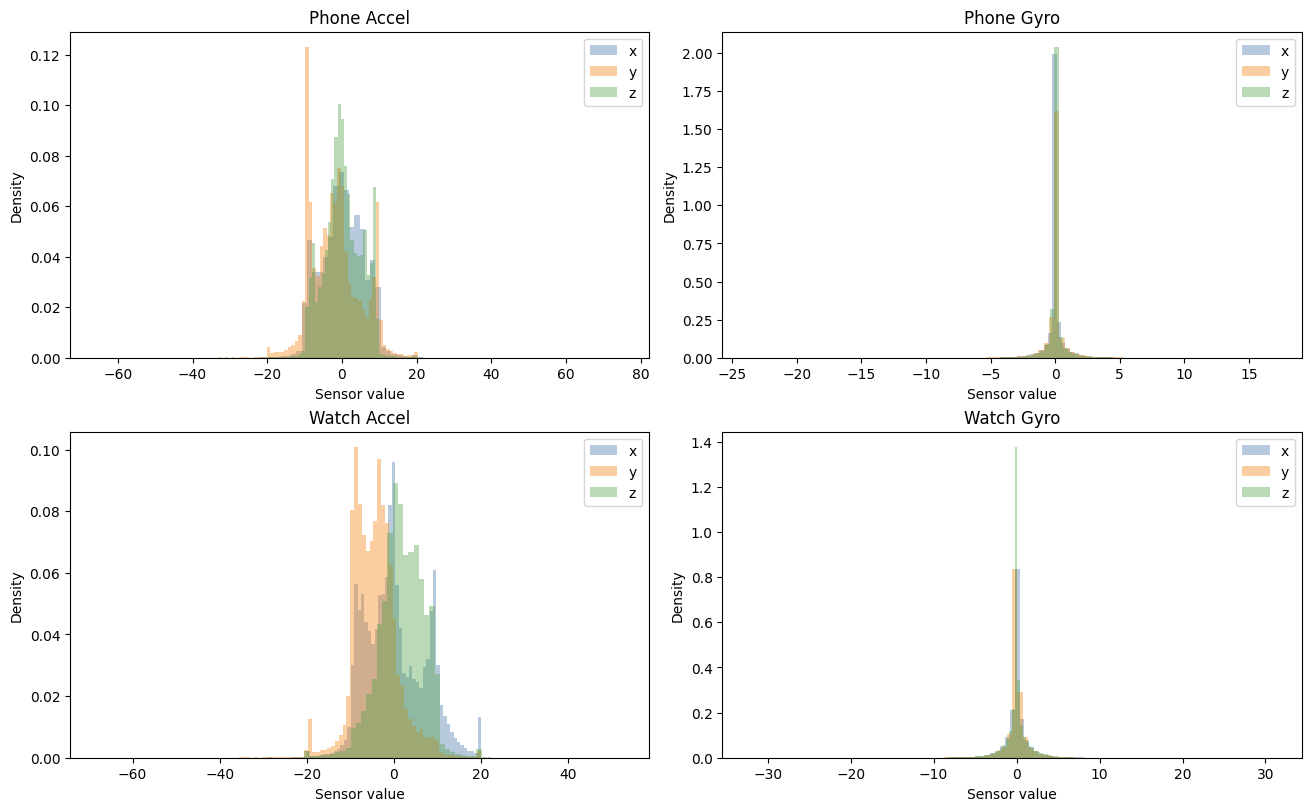

In [87]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 8),
    constrained_layout=True,
)

stream_order = [
    ("phone", "accel"),
    ("phone", "gyro"),
    ("watch", "accel"),
    ("watch", "gyro"),
]

axis_colors = {
    "x": "#4C78A8",
    "y": "#F58518",
    "z": "#54A24B",
}

for ax, (device, sensor) in zip(axes.flat, stream_order):
    subset = data.loc[
        (data["device"] == device)
        & (data["sensor"] == sensor),
        AXES,
    ]

    if len(subset) > 100_000:
        subset = subset.sample(
            100_000,
            random_state=42,
        )

    for axis in AXES:
        ax.hist(
            subset[axis],
            bins=100,
            density=True,
            alpha=0.4,
            color=axis_colors[axis],
            label=axis,
        )

    ax.set_title(f"{device.title()} {sensor.title()}")
    ax.set_xlabel("Sensor value")
    ax.set_ylabel("Density")
    ax.legend()

plt.show()

The accelerometer distributions are broad, asymmetric, and in some cases
multimodal. Their axis-specific centers differ because acceleration includes
gravity and because the phone and watch are carried in different physical
orientations.

Gyroscope measurements are much more sharply concentrated around zero, as
expected during periods with little rotational movement, but they also contain
long tails. The watch gyroscope appears more dispersed than the phone gyroscope,
which agrees with the larger standard deviations in the numerical summary.

These differences show that raw axes from different devices should not be
treated as equivalent physical directions. The plots combine all activities,
so their shapes should not yet be interpreted as activity-specific signal
patterns.

### 5.3 Exact boundary repetition and possible sensor clipping

Very large measurements may represent genuine movements, transient noise, or
sensor saturation.

One sign of clipping is the same boundary value appearing repeatedly. We
therefore count exact occurrences of each observed axis minimum and maximum.
This is a narrow diagnostic: it can detect repeated exact boundaries, but it
cannot rule out clipping represented by several nearby floating-point values.

In [88]:
extreme_rows = []

for (device, sensor), group in data.groupby(
    ["device", "sensor"],
    observed=True,
):
    n = len(group)

    for axis in AXES:
        minimum = group[axis].min()
        maximum = group[axis].max()

        min_count = group[axis].eq(minimum).sum()
        max_count = group[axis].eq(maximum).sum()

        extreme_rows.append({
            "device": device,
            "sensor": sensor,
            "axis": axis,
            "minimum": minimum,
            "min_count": min_count,
            "min_pct": 100 * min_count / n,
            "maximum": maximum,
            "max_count": max_count,
            "max_pct": 100 * max_count / n,
        })

extreme_summary = pd.DataFrame(extreme_rows)

extreme_summary

,device,sensor,axis,minimum,min_count,min_pct,maximum,max_count,max_pct
0,phone,accel,x,-78.477608,1,0.000021,78.477608,26,0.000549
1,phone,accel,y,-78.477608,2,0.000042,64.411659,1,0.000021
2,phone,accel,z,-78.477608,1,0.000021,69.081947,1,0.000021
3,phone,gyro,x,-24.770920,1,0.000028,23.529480,1,0.000028
4,phone,gyro,y,-34.978287,1,0.000028,31.623199,1,0.000028
5,phone,gyro,z,-34.984863,1,0.000028,18.548330,1,0.000028
6,watch,accel,x,-70.631523,1,0.000027,52.113232,1,0.000027
7,watch,accel,y,-78.477608,2,0.000054,35.601967,1,0.000027
8,watch,accel,z,-78.477608,1,0.000027,66.615074,1,0.000027
9,watch,gyro,x,-34.917301,1,0.000030,34.905415,1,0.000030


In [89]:
extreme_summary.assign(
    boundary_pct=lambda df:
        df["min_pct"] + df["max_pct"]
).sort_values(
    "boundary_pct",
    ascending=False,
)

,device,sensor,axis,minimum,min_count,min_pct,maximum,max_count,max_pct,boundary_pct
0,phone,accel,x,-78.477608,1,0.000021,78.477608,26,0.000549,0.000570
7,watch,accel,y,-78.477608,2,0.000054,35.601967,1,0.000027,0.000081
1,phone,accel,y,-78.477608,2,0.000042,64.411659,1,0.000021,0.000063
9,watch,gyro,x,-34.917301,1,0.000030,34.905415,1,0.000030,0.000059
10,watch,gyro,y,-34.900162,1,0.000030,34.069073,1,0.000030,0.000059
11,watch,gyro,z,-34.548958,1,0.000030,18.418898,1,0.000030,0.000059
3,phone,gyro,x,-24.770920,1,0.000028,23.529480,1,0.000028,0.000056
4,phone,gyro,y,-34.978287,1,0.000028,31.623199,1,0.000028,0.000056
5,phone,gyro,z,-34.984863,1,0.000028,18.548330,1,0.000028,0.000056
6,watch,accel,x,-70.631523,1,0.000027,52.113232,1,0.000027,0.000054


Most observed minima and maxima occur only once or twice. This provides no
evidence of widespread exact-boundary clipping.

The main exception is phone-accelerometer x, whose maximum value of
approximately +78.48 m/s² occurs 26 times. Including its single minimum
occurrence, only about 0.00057% of phone-accelerometer measurements lie exactly
at these two boundaries. The repetition is consistent with occasional sensor
saturation, but it affects a negligible fraction of the complete stream type.

The repeated value near −78.48 m/s² across several accelerometer axes also
suggests a shared measurement boundary. However, because most individual
axis-boundary counts are extremely small, these measurements should not be
removed automatically.

This test considers only exact global minima and maxima. It does not detect
possible near-boundary plateaus, quantization, or clipping values that differ
slightly because of numerical representation.

### 5.4 Sensor-distribution findings

Accelerometer and gyroscope measurements have clearly different scales and
distribution shapes. Accelerometer axes are affected by gravity, device
orientation, and physical placement, while gyroscope measurements are centered
more closely around zero and contain narrower central distributions with long
tails.

Extreme measurements are much farther from the central percentile ranges, but
most exact minima and maxima occur only once. There is limited evidence of
occasional boundary saturation, most notably for phone-accelerometer x, but no
evidence that clipping affects a substantial fraction of the dataset.

No measurements are removed based only on global magnitude. Later analysis
should determine whether extreme values are concentrated in particular
activities, subjects, streams, or short temporal intervals.

For preprocessing:

- phone and watch axes should not be assumed to represent equivalent physical
  directions;
- accelerometer and gyroscope channels will require separate scaling;
- any scaling parameters must be learned from training subjects only to avoid
  leakage;
- extreme values should initially be retained and evaluated at the stream and
  window levels before deciding whether clipping, robust scaling, or additional
  quality controls are necessary.

## 6. Representative Raw Signals

This section provides an illustrative view of the unprocessed time-series
signals before magnitude calculation, resampling, windowing, or feature
extraction.

These plots are intended to reveal qualitative temporal structure and possible
recording artifacts. A single subject and short time segment cannot establish
population-level activity patterns or class separability.

### 6.1 Representative activities

To understand the raw time-series structure, we inspect a small set of activities
representing different movement patterns:

- Standing — mostly static
- Walking — periodic locomotion
- Jogging — stronger periodic locomotion
- Typing — localized hand movement

Rather than selecting a subject manually, we choose a subject who has all four
sensor streams available for all selected activities.

In [90]:
REPRESENTATIVE_ACTIVITIES = [
    "Standing",
    "Walking",
    "Jogging",
    "Typing",
]

complete_recordings = (
    data.groupby(
        ["subject_id", "activity"],
        observed=True,
    )
    .apply(
        lambda g: g[["device", "sensor"]]
        .drop_duplicates()
        .shape[0] == 4
    )
    .rename("complete")
    .reset_index()
)

candidate_subjects = (
    complete_recordings[
        complete_recordings["activity"].isin(
            REPRESENTATIVE_ACTIVITIES
        )
        & complete_recordings["complete"]
    ]
    .groupby("subject_id")["activity"]
    .nunique()
)

subject_id = candidate_subjects[
    candidate_subjects == len(REPRESENTATIVE_ACTIVITIES)
].index[0]

print("Selected subject:", subject_id)

Selected subject: 1600


Subject 1600 is the first eligible subject with all four sensor streams for all
four selected activities.

Using one subject throughout prevents differences between plots from being
caused simply by switching participants. The subject was selected according to
stream availability rather than signal appearance.

This remains an illustrative case, not evidence that subject 1600 is typical of
the wider population.

### 6.2 Raw sensor traces

For each activity and device–sensor combination, the first ten seconds are
plotted using elapsed time from the beginning of that individual stream.

Each stream is independently assigned a relative start time of zero. The plots
therefore support within-stream pattern inspection, but matching horizontal
positions across the phone and watch should not be interpreted as exact
sample-level synchronization.

The signals remain on their native timestamps and have not been resampled. The
x, y, and z axes are retained to show the original measurements before any
orientation-independent transformation.

Accelerometer and gyroscope panels have different physical units and independent
vertical scales, so their plotted amplitudes should not be compared directly.

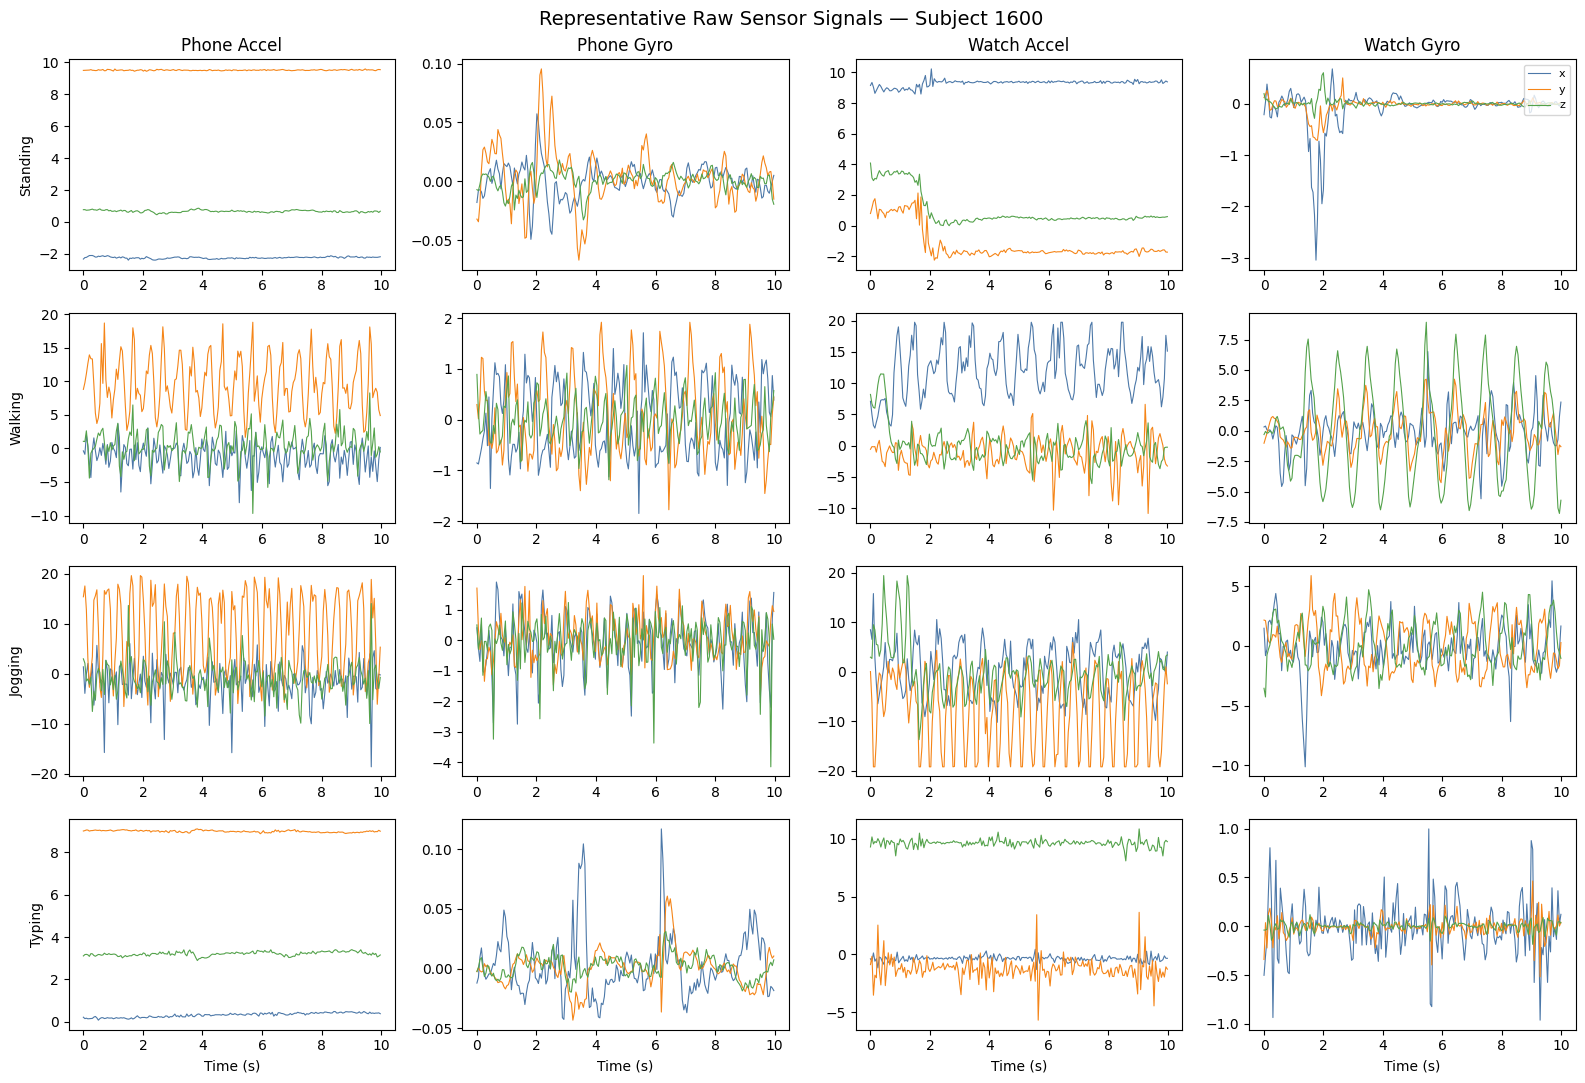

In [91]:
PLOT_SECONDS = 10

stream_order = [
    ("phone", "accel"),
    ("phone", "gyro"),
    ("watch", "accel"),
    ("watch", "gyro"),
]

axis_colors = {
    "x": "#4C78A8",
    "y": "#F58518",
    "z": "#54A24B",
}

fig, axes = plt.subplots(
    len(REPRESENTATIVE_ACTIVITIES),
    len(stream_order),
    figsize=(16, 11),
    sharex=False,
)

for row, activity in enumerate(REPRESENTATIVE_ACTIVITIES):
    for col, (device, sensor) in enumerate(stream_order):

        ax = axes[row, col]

        subset = data[
            (data["subject_id"] == subject_id)
            & (data["activity"] == activity)
            & (data["device"] == device)
            & (data["sensor"] == sensor)
        ].copy()

        subset["relative_time"] = (
            subset["timestamp"] - subset["timestamp"].iloc[0]
        ) / NS_PER_SECOND

        subset = subset[
            subset["relative_time"] <= PLOT_SECONDS
        ]

        for axis in AXES:
            ax.plot(
                subset["relative_time"],
                subset[axis],
                color=axis_colors[axis],
                linewidth=0.8,
                label=axis,
            )

        if row == 0:
            ax.set_title(
                f"{device.title()} {sensor.title()}"
            )

        if col == 0:
            ax.set_ylabel(activity)

        if row == len(REPRESENTATIVE_ACTIVITIES) - 1:
            ax.set_xlabel("Time (s)")

axes[0, -1].legend(
    loc="upper right",
    fontsize=8,
)

fig.suptitle(
    f"Representative Raw Sensor Signals — Subject {subject_id}",
    fontsize=14,
)

plt.tight_layout()
plt.show()

The displayed traces show clear qualitative differences for subject 1600.

Standing is mostly stable, particularly in the phone accelerometer. However,
the watch accelerometer and gyroscope contain a pronounced transient around the
first two seconds, followed by a much steadier signal. This may reflect an
initial posture adjustment, device movement, or recording-start artifact and
shows that the beginning of a labeled activity is not necessarily stationary.

Walking produces repeated oscillations in both accelerometers and especially in
the watch gyroscope. Jogging shows stronger and more rapid fluctuations than
walking for this subject, although the pattern and dominant axis differ between
the phone and watch.

Typing leaves the phone comparatively stable while producing localized changes
and occasional spikes in the watch signals. This is consistent with typing
being primarily a hand-oriented activity and demonstrates why phone and watch
sensors may contribute different information.

The panels use independent vertical scales, so apparent plot height is not a
valid cross-panel amplitude comparison. In addition, these observations come
from one subject and one ten-second segment and should not yet be generalized
to every recording.

### 6.3 Periodic movement example

Locomotion activities often contain repeated motion cycles. To inspect this
structure more clearly, we plot a longer watch-accelerometer segment from the
walking example.

The watch accelerometer is chosen because its periodic structure is visible in
the preceding plot. This is a deliberately illustrative example rather than an
unbiased comparison of sensors or activities.

Frequency is not estimated visually here; quantitative frequency-domain
analysis is performed later.

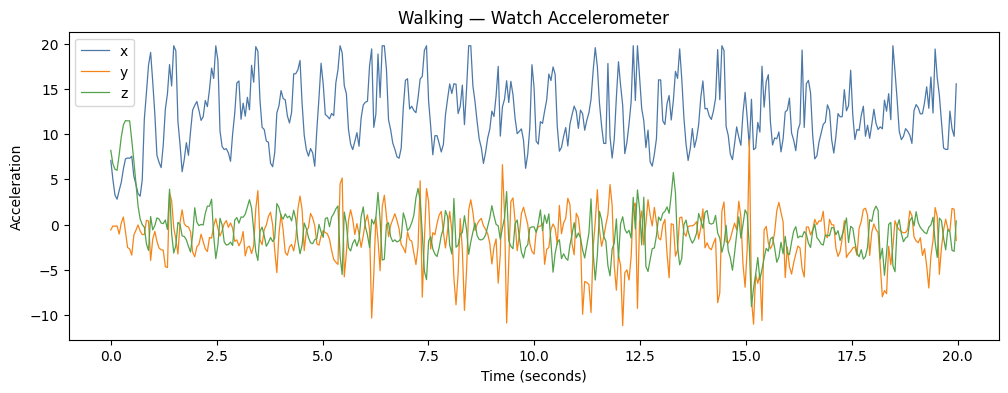

In [92]:
activity = "Walking"
device = "watch"
sensor = "accel"

example = data[
    (data["subject_id"] == subject_id)
    & (data["activity"] == activity)
    & (data["device"] == device)
    & (data["sensor"] == sensor)
].copy()

example["relative_time"] = (
    example["timestamp"] - example["timestamp"].iloc[0]
) / NS_PER_SECOND

example = example[
    example["relative_time"] <= 20
]

fig, ax = plt.subplots(figsize=(12, 4))

for axis in AXES:
    ax.plot(
        example["relative_time"],
        example[axis],
        label=axis,
        color=axis_colors[axis],
        linewidth=0.9,
    )

ax.set(
    title=f"{activity} — Watch Accelerometer",
    xlabel="Time (seconds)",
    ylabel="Acceleration",
)

ax.legend()

plt.show()

The watch-accelerometer x-axis displays repeated oscillations throughout the
20-second walking segment. The cycle amplitudes and shapes vary over time,
showing that even an apparently periodic activity is not perfectly stationary.

The dominant pattern appears on one device-relative axis, while the other axes
contain smaller and less regular fluctuations. Because the dominant axis can
change with device orientation and placement, later activity comparisons should
not depend only on a particular raw axis.

This motivates the use of acceleration magnitude for more
orientation-independent comparisons and window-level frequency analysis for
quantifying periodicity. The observed cadence should be estimated from
timestamps and frequency methods rather than inferred only from visual spacing.

### 6.4 Raw-signal findings

The raw traces contain coherent temporal structure rather than independent
measurements. Static, locomotion, and hand-oriented activities show visibly
different patterns for the selected subject:

- Standing is mostly stable but includes a recording-start transient.
- Walking and jogging contain repeated movement cycles.
- Jogging has stronger and faster fluctuations than walking in this example.
- Typing is more visible on the watch than on the phone.

Phone and watch signals reflect different placements and device-relative axes.
Individual axes cannot be assumed to represent equivalent physical directions
across devices, and independently normalized stream times do not establish
sample-level synchronization.

These plots support later magnitude, window-level, and frequency-domain
analyses, but they do not establish general class differences. Those conclusions
must be based on many subjects and recordings. No samples are removed or
trimmed based only on these illustrative traces.

## 7. Activity Differences Using Signal Magnitude

This section asks whether an orientation-independent signal representation
reveals meaningful differences between activities and sensor modalities.

The analysis uses one summary per subject/activity/device/sensor stream. It
therefore describes between-recording differences without allowing streams with
more measurement rows to dominate.

These whole-recording summaries discard temporal ordering. They are useful for
understanding broad activity patterns, but they are not intended to establish
classifier performance.

### 7.1 Signal magnitude

Raw x, y, and z values depend on device orientation. We therefore calculate the
Euclidean vector magnitude:

\[
\text{magnitude} = \sqrt{x^2 + y^2 + z^2}
\]

Magnitude is invariant to rotations of the coordinate axes, but it discards
movement direction. It also does not remove differences caused by device
placement, sensor characteristics, or the way subjects perform an activity.

Accelerometer magnitude is measured in m/s² and includes gravity. Gyroscope
magnitude is measured in rad/s and represents total angular speed. Magnitudes
from the two sensor types should therefore not be compared numerically as though
they shared a common scale.

In [93]:
magnitude_data = data[
    ["subject_id", "activity", "device", "sensor"]
].copy()

magnitude_data["magnitude"] = np.sqrt(
    data["x"] ** 2
    + data["y"] ** 2
    + data["z"] ** 2
)

In [94]:
magnitude_summary = (
    magnitude_data
    .groupby(
        ["subject_id", "activity", "device", "sensor"],
        observed=True,
    )
    .agg(
        median_magnitude=("magnitude", "median"),
        std_magnitude=("magnitude", "std"),
    )
    .reset_index()
)

magnitude_summary.head()

,subject_id,activity,device,sensor,median_magnitude,std_magnitude
0,1600,Brushing Teeth,phone,accel,9.196246,0.040283
1,1600,Brushing Teeth,phone,gyro,0.022857,0.060807
2,1600,Brushing Teeth,watch,accel,9.753567,0.903719
3,1600,Brushing Teeth,watch,gyro,0.781737,0.468059
4,1600,Clapping,phone,accel,9.352214,0.114084


Each row of `magnitude_summary` represents one available
subject/activity/device/sensor stream rather than one individual measurement.

- `median_magnitude` describes the typical magnitude level across the stream.
- `std_magnitude` describes how much magnitude varies during the complete
  recording.

Magnitude standard deviation is a useful motion-variability measure, but it is
not determined only by activity intensity. Recording transitions, isolated
extreme measurements, and nonstationary behavior can also increase it.
Furthermore, summarizing the complete recording removes information about the
order and frequency of movement cycles.

### 7.2 Motion variability by activity

We compare stream-level magnitude variability across subjects for every activity
and device–sensor combination.

Using one value per stream gives approximately equal weight to each available
subject recording, regardless of sampling frequency or raw row count.

The boxplots hide visual fliers to keep the central distributions readable, but
those observations remain in the data. Each panel also has its own horizontal
scale, so numerical variability should be compared using the axis values rather
than only the apparent widths of the boxes.

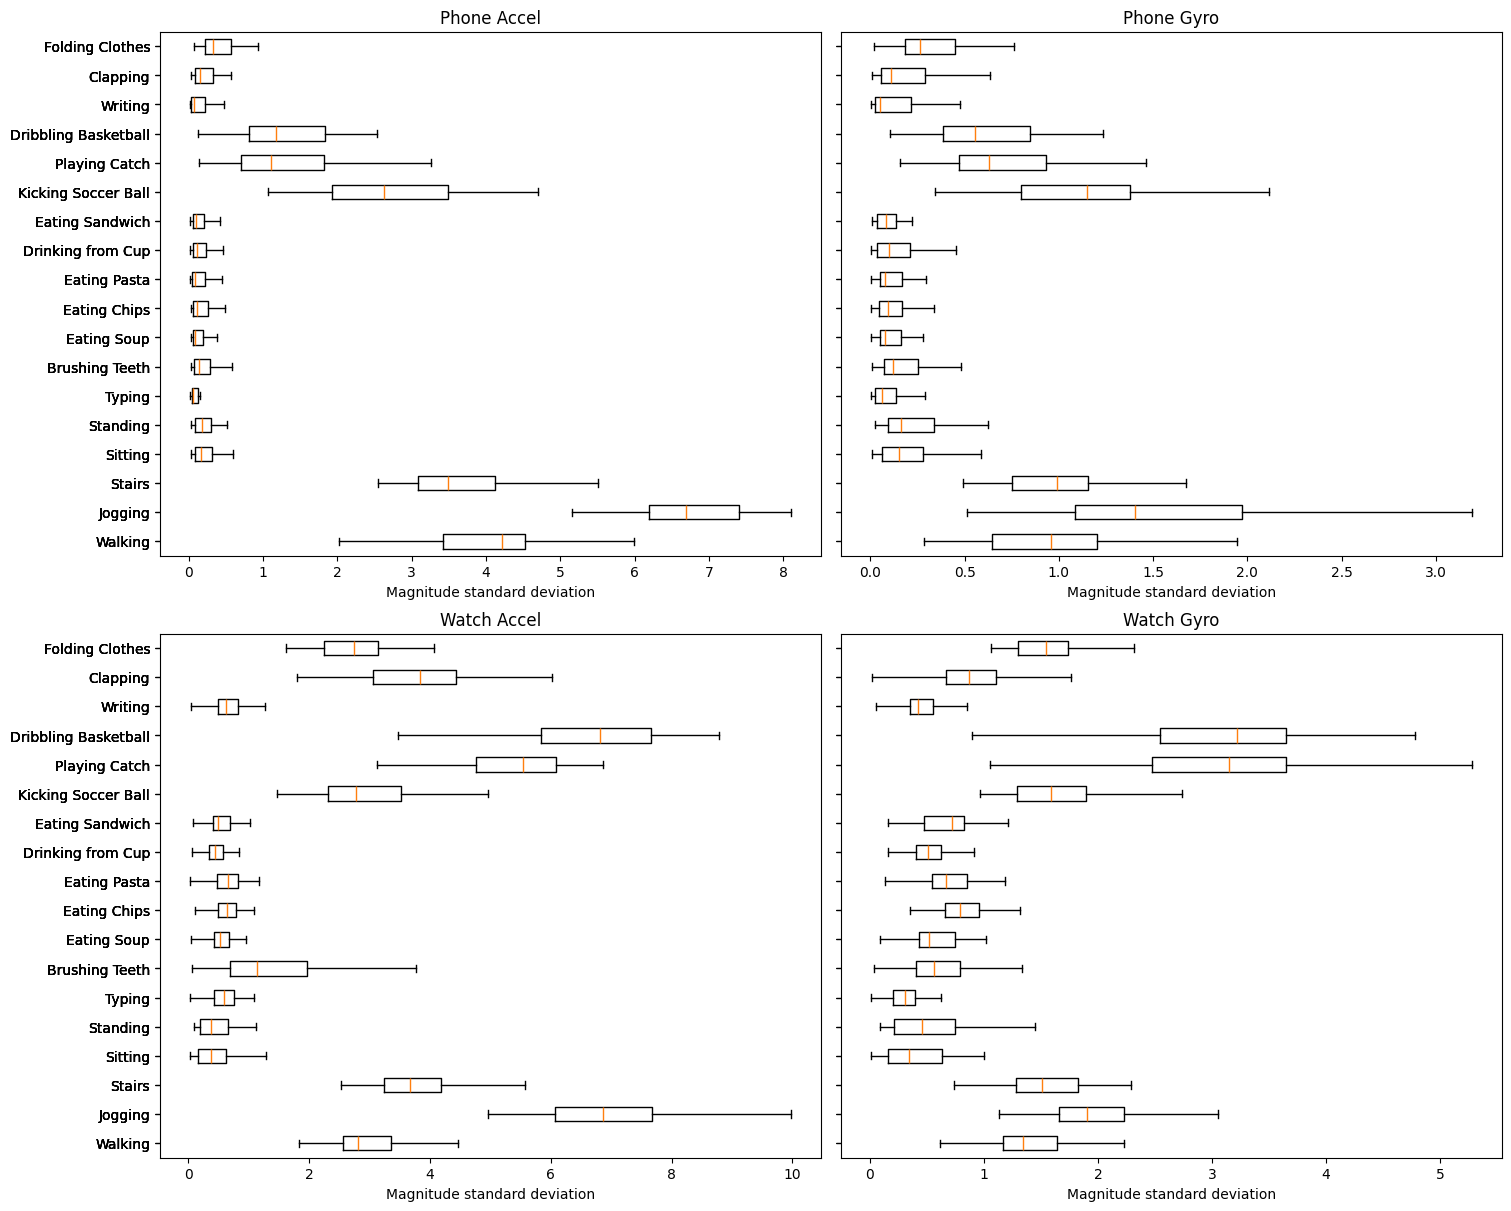

In [95]:
stream_order = [
    ("phone", "accel"),
    ("phone", "gyro"),
    ("watch", "accel"),
    ("watch", "gyro"),
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 12),
    sharey=True,
    constrained_layout=True,
)

for ax, (device, sensor) in zip(axes.flat, stream_order):

    subset = magnitude_summary[
        (magnitude_summary["device"] == device)
        & (magnitude_summary["sensor"] == sensor)
    ]

    values = [
        subset.loc[
            subset["activity"] == activity,
            "std_magnitude",
        ].dropna()
        for activity in activities
    ]

    ax.boxplot(
        values,
        vert=False,
        tick_labels=activities,
        showfliers=False,
    )

    ax.set_title(f"{device.title()} {sensor.title()}")
    ax.set_xlabel("Magnitude standard deviation")

plt.show()

The variability distributions reveal both activity and modality effects.

For the phone sensors, locomotion activities—especially Jogging, Walking, and
Stairs—show high variability. Kicking Soccer Ball is also prominent, while most
eating, writing, typing, and static activities have substantially lower phone
variability.

The watch produces a different pattern. Jogging remains highly variable, but
hand-oriented activities such as Dribbling Basketball, Playing Catch, Clapping,
and Folding Clothes become much more prominent. Typing and the eating
activities also show more watch variability than phone variability, although
their levels remain lower than the large arm-motion activities.

Sitting and Standing have low variability across all four modalities. However,
their distributions overlap with several fine-motor activities, showing that
overall motion variability alone cannot distinguish every class.

The distributions also have substantial between-subject spread, particularly
for high-motion activities. This suggests that subjects differ in movement
style or intensity even when performing the same labeled activity.

### 7.3 Activity-level magnitude summary

The boxplots show the distribution of stream-level variability across subjects.
We now summarize each activity and modality using the median of those
recording-level values.

The first table retains both the median magnitude level and median variability.
The pivoted table emphasizes median variability because it provides the clearest
summary of relative motion across activities.

Accelerometer and gyroscope values remain in different physical units, so
comparisons should be made across activities within a modality rather than
directly between sensor types.

In [96]:
activity_magnitude = (
    magnitude_summary
    .groupby(
        ["activity", "device", "sensor"],
        observed=True,
    )
    .agg(
        median_level=("median_magnitude", "median"),
        median_variability=("std_magnitude", "median"),
    )
    .reset_index()
)

activity_magnitude

,activity,device,sensor,median_level,median_variability
0,Brushing Teeth,phone,accel,9.797863,0.144847
1,Brushing Teeth,phone,gyro,0.036648,0.119968
2,Brushing Teeth,watch,accel,9.970576,1.136601
3,Brushing Teeth,watch,gyro,0.841255,0.558399
4,Clapping,phone,accel,9.745472,0.145797
...,...,...,...,...,...
67,Walking,watch,gyro,2.412047,1.344335
68,Writing,phone,accel,9.715368,0.068761
69,Writing,phone,gyro,0.017017,0.052130
70,Writing,watch,accel,9.771653,0.626752


In [97]:
activity_magnitude.pivot(
    index="activity",
    columns=["device", "sensor"],
    values="median_variability",
).reindex(activities)

device                   phone               watch          
sensor                   accel      gyro     accel      gyro
activity                                                    
Walking               4.221200  0.959535  2.810597  1.344335
Jogging               6.690850  1.404379  6.867442  1.906839
Stairs                3.486727  0.988438  3.661190  1.506837
Sitting               0.164067  0.152617  0.374985  0.345862
Standing              0.173850  0.164454  0.368789  0.453667
Typing                0.063714  0.061454  0.587701  0.307119
Brushing Teeth        0.144847  0.119968  1.136601  0.558399
Eating Soup           0.090095  0.076270  0.525474  0.517060
Eating Chips          0.116656  0.094722  0.632491  0.792560
Eating Pasta          0.088749  0.077077  0.654422  0.665879
Drinking from Cup     0.110064  0.100084  0.435755  0.508831
Eating Sandwich       0.100815  0.084258  0.489996  0.717981
Kicking Soccer Ball   2.628877  1.149636  2.782976  1.592617
Playing Catch         1.106677  0.627645  5.542979  3.148003
Dribbling Basketball  1.169066  0.556442  6.820242  3.219257
Writing               0.068761  0.052130  0.626752  0.420681
Clapping              0.145797  0.108350  3.828840  0.870452
Folding Clothes       0.330666  0.262095  2.742627  1.540414

The median summaries confirm the modality-specific patterns visible in the
boxplots.

Jogging has the highest or nearly highest median variability for both phone and
watch accelerometers. Walking and Stairs are also consistently variable across
devices.

Dribbling Basketball and Playing Catch are especially prominent on the watch:
their median watch-accelerometer variability is approximately 6.82 and 5.54,
and their watch-gyroscope variability is approximately 3.22 and 3.15. Their
phone variability is much lower, showing the additional information provided by
a wrist-worn sensor.

Clapping and Folding Clothes follow the same general pattern, with much stronger
watch than phone variability. Conversely, Kicking Soccer Ball is highly visible
on both devices because it involves substantial lower-body movement together
with device motion.

Sitting, Standing, Typing, Writing, and the eating activities occupy overlapping
low-variability ranges in several modalities. These activities cannot be
reliably separated using one whole-recording intensity statistic.

### 7.4 Magnitude findings

Signal magnitude reduces dependence on the orientation of individual axes and
reveals meaningful activity-level differences. Large locomotion activities are
prominent across devices, while many hand-oriented activities are substantially
more visible on the watch than on the phone.

This demonstrates that the phone and watch provide complementary information.
It also shows that the usefulness of a sensor depends on the type of activity
being recognized.

Magnitude variability alone is insufficient for classification. Several static,
eating, writing, and other fine-motor activities have overlapping whole-recording
distributions, and high-motion activities show considerable between-subject
variation.

Later modeling should therefore retain temporal information through
window-level features or sequence models. Magnitude can complement the original
axes, but should not automatically replace them because direction information
may still be predictive. Any scaling or normalization parameters must be learned
from training subjects only, and evaluation must continue to respect subject
boundaries.

## 8. Window-Level EDA

This section moves from complete activity recordings to short temporal segments,
which are closer to the units that an activity-recognition model will consume.

The current windows are constructed for exploratory analysis. They are used to
study local signal variation and expose window-quality requirements; they are
not yet the finalized training examples.

### 8.1 Preliminary fixed-duration windows

Each sensor stream is divided into non-overlapping five-second timestamp bins.
Timestamp-based boundaries are used because a fixed number of rows would
represent different durations at different sampling frequencies.

The final incomplete bin at the end of each stream is excluded using the
recording's elapsed timestamp span.

No interpolation, resampling, minimum-sample requirement, or within-window gap
check is applied at this stage. A retained bin is therefore nominally five
seconds wide, but it may contain sparse observations or an internal temporal
gap.

Window times are also defined independently from the beginning of each stream.
Matching `window_id` values across phone and watch streams should not be assumed
to represent exactly synchronized real-world intervals.

In [98]:
WINDOW_SECONDS = 5

window_data = data[
    STREAM_KEYS + ["timestamp", "x", "y", "z"]
].copy()

window_data["magnitude"] = np.sqrt(
    window_data["x"] ** 2
    + window_data["y"] ** 2
    + window_data["z"] ** 2
)

stream_start = (
    window_data
    .groupby(STREAM_KEYS, observed=True)["timestamp"]
    .transform("min")
)

window_data["relative_time_s"] = (
    window_data["timestamp"] - stream_start
) / NS_PER_SECOND

window_data["window_id"] = (
    window_data["relative_time_s"] // WINDOW_SECONDS
).astype(int)

In [99]:
stream_durations = stream_summary[
    STREAM_KEYS + ["duration_seconds"]
]

window_data = window_data.merge(
    stream_durations,
    on=STREAM_KEYS,
    how="left",
)

window_data = window_data[
    (window_data["window_id"] + 1) * WINDOW_SECONDS
    <= window_data["duration_seconds"]
]

Each retained `window_id` identifies a fixed five-second interval on its
individual stream's relative time axis.

This avoids equating, for example, 100 samples from a 20 Hz stream with 100
samples from a 50 Hz stream. However, equal timestamp-bin width does not imply
equal sample count, complete temporal coverage, or cross-device synchronization.

Before these bins can become modeling windows, they will require checks for:

- sufficient sample count and time coverage;
- large internal timestamp gaps;
- continuity within a recording segment;
- consistent sampling after resampling;
- valid alignment when multiple device streams are fused.

### 8.2 Preliminary window-level motion features

For each retained bin, we calculate simple magnitude-based summaries:

- sample count;
- mean magnitude;
- magnitude standard deviation;
- minimum and maximum magnitude;
- magnitude range.

These features summarize local signal level and variation but discard the order
of samples within the window. Standard deviation and range are also sensitive
to isolated extreme measurements.

Accelerometer and gyroscope magnitudes have different physical units and scales.
Their feature values should be interpreted within a device–sensor combination,
not pooled as though they formed one common physical distribution.

In [100]:
window_features = (
    window_data
    .groupby(
        STREAM_KEYS + ["window_id"],
        observed=True,
    )
    .agg(
        samples=("magnitude", "size"),
        mean_magnitude=("magnitude", "mean"),
        std_magnitude=("magnitude", "std"),
        min_magnitude=("magnitude", "min"),
        max_magnitude=("magnitude", "max"),
    )
    .reset_index()
)

window_features["range_magnitude"] = (
    window_features["max_magnitude"]
    - window_features["min_magnitude"]
)

window_features.head()

,subject_id,activity,device,sensor,window_id,samples,mean_magnitude,std_magnitude,min_magnitude,max_magnitude,range_magnitude
0,1600,Brushing Teeth,phone,accel,0,100,9.204468,0.076092,9.025225,9.438516,0.413291
1,1600,Brushing Teeth,phone,accel,1,99,9.193559,0.067989,8.951397,9.492420,0.541023
2,1600,Brushing Teeth,phone,accel,2,99,9.201385,0.030221,9.132258,9.272527,0.140268
3,1600,Brushing Teeth,phone,accel,3,100,9.201271,0.026693,9.135323,9.262804,0.127481
4,1600,Brushing Teeth,phone,accel,4,99,9.193427,0.032623,9.103140,9.258729,0.155589


In [101]:
print(f"Windows created: {len(window_features):,}")

window_features[
    [
        "samples",
        "mean_magnitude",
        "std_magnitude",
        "range_magnitude",
    ]
].describe()

Windows created: 127,513


,samples,mean_magnitude,std_magnitude,range_magnitude
count,127513.000000,127513.000000,127513.000000,127513.000000
mean,117.522496,5.766855,1.215852,6.195798
std,44.679570,4.880047,1.824696,8.703635
min,7.000000,0.000924,0.000000,0.000000
25%,100.000000,0.475184,0.060457,0.355588
50%,100.000000,9.146523,0.447103,2.476313
75%,101.000000,9.889960,1.490710,8.169224
max,504.000000,37.575352,20.009472,101.963013


The preliminary procedure creates 127,513 windows.

The median window contains 100 samples, and the interquartile range is
100–101 samples. This is consistent with the dominant sampling cadence of
approximately 20 Hz observed in Part 3.

However, sample counts range from 7 to 504. The upper end is consistent with
streams having much higher local sampling cadences, while very low counts
indicate sparse or interrupted bins. Such windows should not automatically be
used for modeling merely because their nominal timestamp interval is five
seconds.

At least one window has zero magnitude variability and zero range, while the
largest standard deviation and range are approximately 20.01 and 101.96. These
extremes may reflect genuine intense motion, sensor-boundary values, sparse
coverage, or recording irregularities and require window-level quality checks.

The displayed descriptive statistics pool accelerometer and gyroscope windows.
Because those sensors have different units, the pooled magnitude-feature means
and percentiles are useful only as broad diagnostics, not as physically
interpretable global summaries.

### 8.3 Activity differences across accelerometer windows

We compare magnitude variability across activities using the preliminary phone
and watch accelerometer windows.

Each activity is represented by many short segments, allowing us to see
within-activity variation that was hidden by the whole-recording summaries in
Section 7.

The boxplots hide visual fliers for readability, but those windows remain in the
data. Windows from the same subject and recording are also not statistically
independent, so these plots are descriptive rather than inferential.

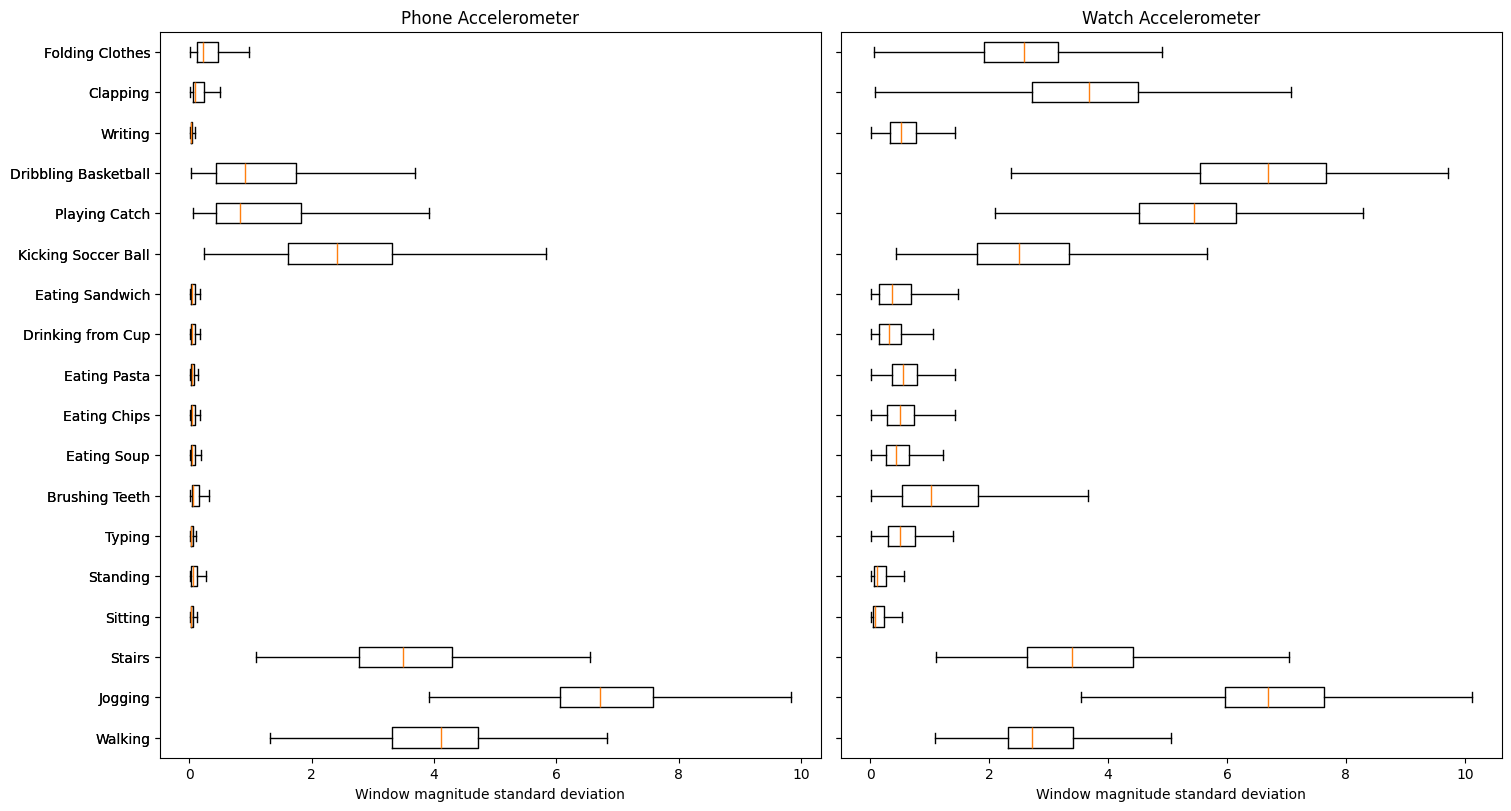

In [102]:
accel_windows = window_features[
    window_features["sensor"] == "accel"
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 8),
    sharey=True,
    constrained_layout=True,
)

for ax, device in zip(axes, ["phone", "watch"]):

    subset = accel_windows[
        accel_windows["device"] == device
    ]

    values = [
        subset.loc[
            subset["activity"] == activity,
            "std_magnitude",
        ].dropna()
        for activity in activities
    ]

    ax.boxplot(
        values,
        vert=False,
        tick_labels=activities,
        showfliers=False,
    )

    ax.set_title(f"{device.title()} Accelerometer")
    ax.set_xlabel("Window magnitude standard deviation")

plt.show()

In [103]:
activity_window_summary = (
    window_features
    .groupby(
        ["activity", "device", "sensor"],
        observed=True,
    )
    .agg(
        windows=("window_id", "size"),
        median_variability=("std_magnitude", "median"),
        median_range=("range_magnitude", "median"),
    )
    .reset_index()
)

activity_window_summary.head()

,activity,device,sensor,windows,median_variability,median_range
0,Brushing Teeth,phone,accel,1796,0.056156,0.314699
1,Brushing Teeth,phone,gyro,1786,0.026926,0.132962
2,Brushing Teeth,watch,accel,1786,1.024705,5.079101
3,Brushing Teeth,watch,gyro,1785,0.451247,2.234335
4,Clapping,phone,accel,1794,0.093002,0.541994


The window-level distributions retain the broad patterns observed in the
whole-recording analysis while revealing substantial variation within each
activity.

For the phone accelerometer, Jogging has the highest typical local variability,
followed by Walking and Stairs. Kicking Soccer Ball is also relatively variable.
Sitting, Standing, Typing, Writing, and the eating activities are concentrated
near low variability.

The watch accelerometer highlights hand-oriented motion more strongly.
Dribbling Basketball and Playing Catch have particularly high variability,
while Clapping and Folding Clothes are also much more prominent on the watch
than on the phone. This again demonstrates the complementary information
provided by the two device placements.

Many activity distributions are broad and overlapping. Even active classes such
as Walking, Stairs, Kicking Soccer Ball, Playing Catch, and Dribbling Basketball
share substantial ranges. Some activities also contain both quiet and active
windows, showing that one activity recording is not necessarily stationary
throughout its full duration.

A single window-level intensity statistic is therefore insufficient for
classification. Temporal shape, periodicity, multiple features, and information
from different sensors will be needed to distinguish overlapping activities.

### 8.4 Window-level findings and modeling requirements

Timestamp-based windowing correctly avoids treating a fixed number of samples as
a fixed duration. The resulting five-second bins reveal meaningful local
activity differences and expose within-activity variation that complete-recording
summaries conceal.

However, the current bins are not yet suitable as final model inputs:

- sample counts vary from 7 to 504;
- some bins may contain internal temporal gaps;
- long gaps have not yet been used to split streams into continuous segments;
- phone and watch window identifiers are independently defined;
- no common sampling grid has been created;
- extreme and zero-variability windows have not been investigated.

Before modeling, continuous segments should be identified, incomplete or sparse
windows should be handled using an explicit quality rule, and retained signals
should be resampled consistently. Multimodal windows will additionally require
a justified cross-device alignment procedure.

Window counts should be recomputed only after those decisions, because the
quality filters, required sensor combination, window length, and overlap will
determine the actual class support available to the classifier.

All train/test splitting must occur by subject. Windows from the same subject or
recording must never be divided across training and evaluation sets, and choices
such as window length, overlap, resampling rate, and quality thresholds should
be selected using training subjects only.

## 9. Frequency-Domain Analysis

This section examines whether activities differ in the rate and strength of
repeated motion.

Frequency-domain information complements magnitude variability: two activities
may have similar motion intensity but differ in cadence or periodicity.
Conversely, a frequency estimate is meaningful only when the signal contains a
sufficiently strong repetitive component.

The current analysis uses Lomb–Scargle periodograms because timestamps are not
perfectly uniform. It remains preliminary because the window-quality and
continuity requirements identified in Section 8 have not yet been applied.

### 9.1 Frequency characteristics of illustrative activities

We first inspect the watch-accelerometer magnitude spectra for Standing,
Walking, Jogging, and Typing from subject 1600.

Magnitude is centered before calculating the periodogram, removing the constant
component and most of the contribution from gravity. The analysis uses the
actual timestamps rather than assuming perfectly uniform sampling.

These complete-recording spectra are illustrative examples. They show what
periodic and nonperiodic signals can look like, but they do not establish
population-level activity differences.

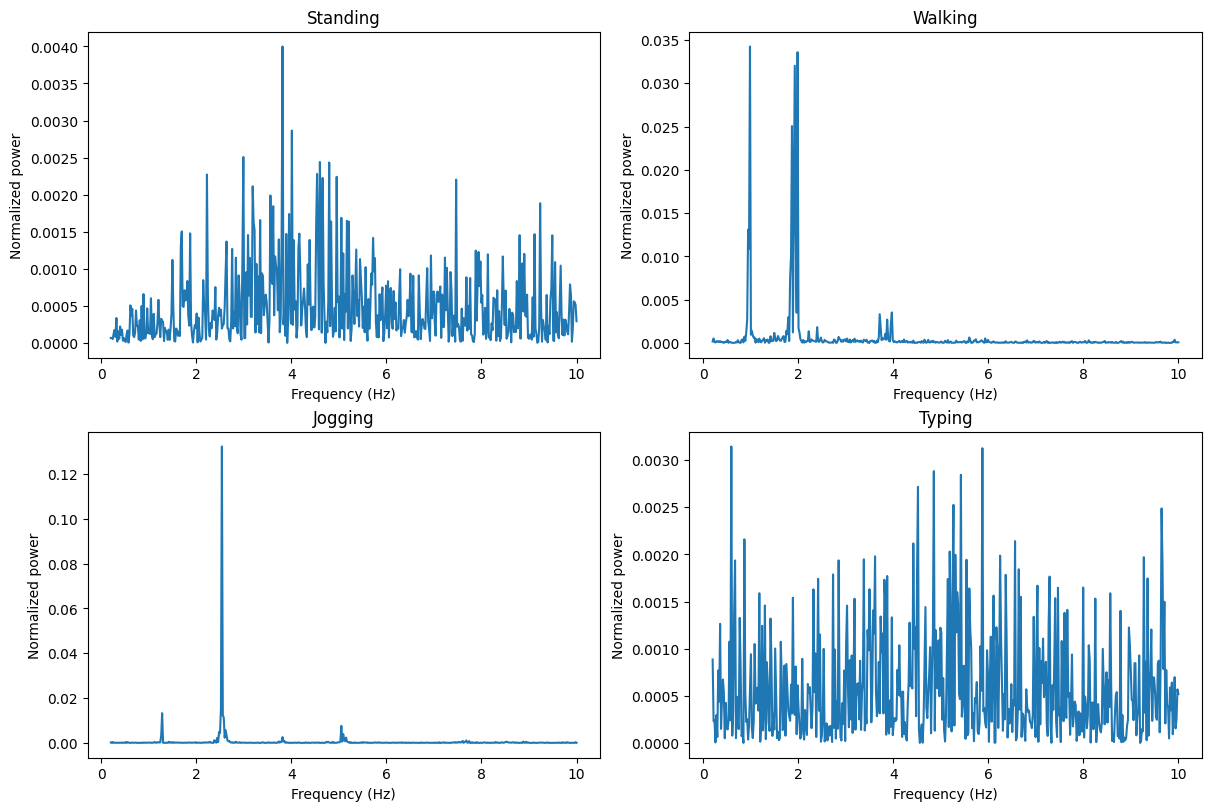

In [104]:
from scipy.signal import lombscargle

FREQUENCY_ACTIVITIES = [
    "Standing",
    "Walking",
    "Jogging",
    "Typing",
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
    constrained_layout=True,
)

frequencies = np.linspace(0.2, 10, 500)
angular_frequencies = 2 * np.pi * frequencies

for ax, activity in zip(axes.flat, FREQUENCY_ACTIVITIES):

    subset = data[
        (data["subject_id"] == subject_id)
        & (data["activity"] == activity)
        & (data["device"] == "watch")
        & (data["sensor"] == "accel")
    ].copy()

    time_s = (
        subset["timestamp"].to_numpy()
        - subset["timestamp"].iloc[0]
    ) / NS_PER_SECOND

    magnitude = np.sqrt(
        subset["x"].to_numpy() ** 2
        + subset["y"].to_numpy() ** 2
        + subset["z"].to_numpy() ** 2
    )

    # Remove the constant component, including most of gravity.
    magnitude = magnitude - magnitude.mean()

    power = lombscargle(
        time_s,
        magnitude,
        angular_frequencies,
        normalize=True,
    )

    ax.plot(frequencies, power)

    ax.set(
        title=activity,
        xlabel="Frequency (Hz)",
        ylabel="Normalized power",
    )

plt.show()

The illustrative spectra show a strong contrast between locomotion and
low-motion activities.

Walking has concentrated peaks near approximately 1 Hz and 2 Hz, together with
weaker higher-frequency components. These peaks may represent a movement cadence
and its harmonics; the strongest magnitude peak does not necessarily correspond
directly to one complete gait cycle.

Jogging has a particularly strong, narrow peak near approximately 2.6 Hz and
weaker peaks at related frequencies. Its spectrum is more concentrated and has
substantially greater normalized power than the Standing or Typing examples.

Standing and Typing have much weaker, broadly distributed spectra without one
clearly dominant periodic component. Their small peaks are more likely to
represent noise, isolated movements, or irregular fine-motor behavior than a
stable activity cadence.

The panels have independent vertical scales, so peak heights should be compared
using their numerical axes rather than only their visual height. These examples
suggest that both peak location and periodicity strength may be useful features.

### 9.2 Preliminary dominant frequency across activity windows

To move beyond one subject, we estimate the frequency with the largest
Lomb–Scargle power in each preliminary five-second watch-accelerometer window.

Only watch accelerometer data are used in this comparison, so the conclusions
apply to that modality rather than to every sensor stream.

The estimate is preliminary for several reasons:

- sparse or internally gapped windows have not yet been excluded;
- windows with little or no magnitude variation are not filtered;
- the frequency search always returns a maximum, even when all power values are
  weak;
- the same 0.2–10 Hz search range is used despite varying sample counts and
  effective sampling rates.

A frequency near the lower limit represents only about one cycle within a
five-second window, while the practical frequency resolution is approximately
\(1 / 5 = 0.2\) Hz. The many decimal places produced by the search grid should
therefore not be interpreted as measurement precision.

In [105]:
watch_accel = window_data[
    (window_data["device"] == "watch")
    & (window_data["sensor"] == "accel")
].copy()

In [106]:
def dominant_frequency(group, min_hz=0.2, max_hz=10, n_freqs=300):
    if len(group) < 10:
        return np.nan

    time_s = group["relative_time_s"].to_numpy()

    magnitude = np.sqrt(
        group["x"].to_numpy() ** 2
        + group["y"].to_numpy() ** 2
        + group["z"].to_numpy() ** 2
    )

    magnitude = magnitude - magnitude.mean()

    frequencies = np.linspace(
        min_hz,
        max_hz,
        n_freqs,
    )

    power = lombscargle(
        time_s,
        magnitude,
        2 * np.pi * frequencies,
        normalize=True,
    )

    return frequencies[np.argmax(power)]

In [107]:
window_frequency = (
    watch_accel
    .groupby(
        ["subject_id", "activity", "window_id"],
        observed=True,
    )
    .apply(dominant_frequency)
    .rename("dominant_frequency_hz")
    .reset_index()
)

window_frequency.head()

,subject_id,activity,window_id,dominant_frequency_hz
0,1600,Brushing Teeth,0,2.920401
1,1600,Brushing Teeth,1,3.805351
2,1600,Brushing Teeth,2,3.182609
3,1600,Brushing Teeth,3,2.985953
4,1600,Brushing Teeth,4,3.444816


`dominant_frequency_hz` records the frequency grid point with the greatest
normalized Lomb–Scargle power in each window.

For a strongly periodic window, this can provide a useful estimate of local
movement cadence or one of its harmonics. For a quiet or irregular window,
however, it records the largest noise-related peak even when no meaningful
periodicity is present.

Dominant frequency should therefore eventually be paired with features such as
maximum normalized power, peak prominence, or the proportion of spectral power
near the dominant peak. A minimum periodicity-strength rule may also be needed
before a peak frequency is considered interpretable.

### 9.3 Dominant-frequency distributions across activities

We compare the preliminary dominant-frequency distributions across activities
using watch-accelerometer windows.

The boxplots hide visual fliers but retain those windows in the data. Multiple
windows come from the same subjects and recordings, so the distributions are
descriptive and should not be treated as collections of independent
observations.

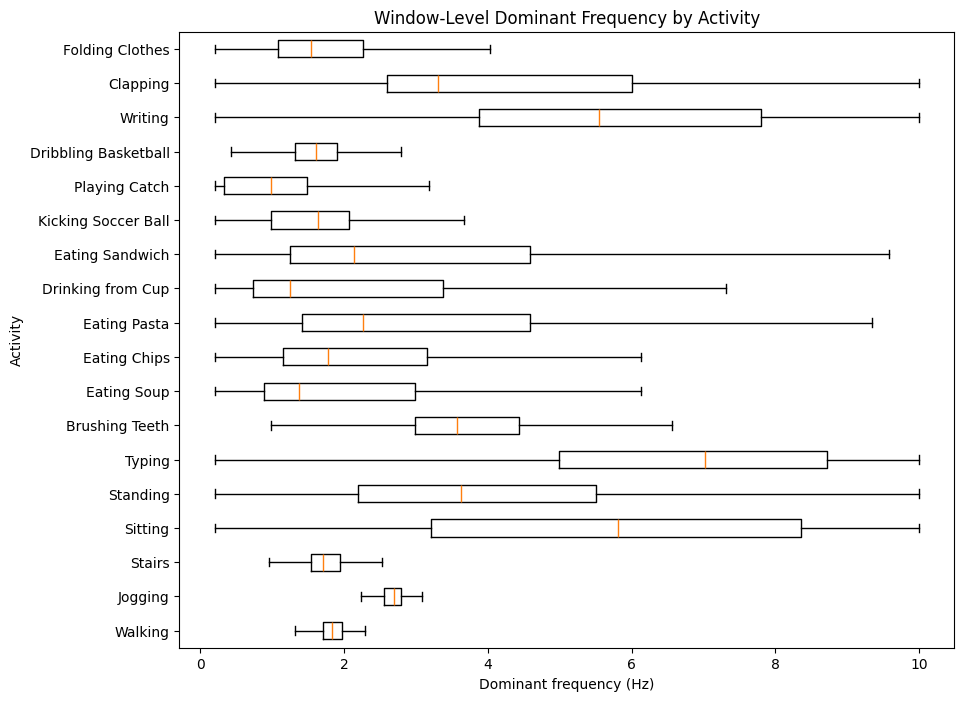

In [108]:
values = [
    window_frequency.loc[
        window_frequency["activity"] == activity,
        "dominant_frequency_hz",
    ].dropna()
    for activity in activities
]

fig, ax = plt.subplots(figsize=(10, 8))

ax.boxplot(
    values,
    vert=False,
    tick_labels=activities,
    showfliers=False,
)

ax.set(
    xlabel="Dominant frequency (Hz)",
    ylabel="Activity",
    title="Window-Level Dominant Frequency by Activity",
)

plt.show()

Several repetitive activities occupy relatively narrow frequency ranges.

Walking is concentrated around approximately 1.8 Hz, Jogging around 2.6 Hz, and
Stairs around 1.7 Hz. Dribbling Basketball also has a narrow distribution near
approximately 1.6 Hz. These stable ranges are consistent with repeated movement
cycles.

Other activities have much broader distributions. Sitting, Standing, Typing,
Writing, Clapping, and several eating activities span large portions of the
frequency search range. Their high median frequency estimates should not be
interpreted as evidence of rapid periodic motion. Because the method is forced
to select a maximum, weak and noisy spectra can produce arbitrary dominant
frequencies anywhere in the search interval.

Playing Catch, Kicking Soccer Ball, and Folding Clothes show intermediate
patterns, while Clapping has a particularly broad distribution that may reflect
variable tempo, short movement bursts, and quiet intervals.

The narrow bands for rhythmic activities suggest that frequency can complement
magnitude variability. The broad distributions for low-periodicity activities
show that peak frequency alone is not a reliable standalone feature.

### 9.4 Frequency-domain findings and requirements

The representative spectra show that Walking and Jogging contain strong,
concentrated periodic components, whereas Standing and Typing have much weaker
and more diffuse frequency content.

Across windows, rhythmic activities such as Walking, Jogging, Stairs, and
Dribbling Basketball occupy relatively stable dominant-frequency ranges.
However, forcing every window to have a dominant frequency produces unstable
and potentially misleading estimates for static, irregular, or weak-motion
activities.

Before frequency features are used for modeling:

- windows should be restricted to continuous, sufficiently sampled segments;
- zero-variation and weak-signal windows should be handled explicitly;
- the analyzed frequency range should respect the final sampling rate;
- peak frequency should be accompanied by peak power or prominence;
- harmonic structure and band-level power should be considered;
- frequency precision should reflect the window duration rather than the dense
  search grid;
- the influence of window length on frequency resolution should be evaluated
  using training subjects only.

Frequency information is therefore useful as a complement to time-domain
magnitude and variability features, not as a standalone activity classifier.
All subject-wise splitting and window-quality decisions from Section 8 remain
necessary.

## 10. Subject Variability

This section examines how much the same activity-level motion summary differs
across participants.

Between-subject differences may reflect movement style, body characteristics,
device placement, activity execution, or recording conditions. The analysis is
descriptive and cannot determine which of these factors caused an observed
difference.

Understanding this variation is important because the eventual model must
generalize to subjects who were not present during training.

### 10.1 Subject-to-subject variability

We use the complete-recording magnitude summaries from Section 7 rather than
individual sensor rows. This prevents subjects with higher sampling frequencies
from contributing more heavily merely because they have more measurements.

For each subject/activity pair, the current calculation takes the median
accelerometer magnitude variability across the available phone and watch
streams.

This creates one compact value per subject and activity, but it also combines
two different device placements. When both accelerometers are available, the
value blends phone and watch behavior. When one accelerometer is missing, it is
based only on the remaining device. The result should therefore be interpreted
as a preliminary combined-device summary rather than a pure measure of subject
movement style.

In [109]:
subject_activity_variability = (
    magnitude_summary[
        magnitude_summary["sensor"] == "accel"
    ]
    .groupby(
        ["subject_id", "activity"],
        observed=True,
    )["std_magnitude"]
    .median()
    .reset_index()
)

subject_activity_variability.head()

,subject_id,activity,std_magnitude
0,1600,Brushing Teeth,0.472001
1,1600,Clapping,1.903940
2,1600,Dribbling Basketball,4.475892
3,1600,Drinking from Cup,0.117140
4,1600,Eating Chips,0.301024


Each row represents one available subject/activity pair and contains a combined
accelerometer magnitude-variability value.

This gives approximately equal weight to each subject/activity recording and
avoids raw-row weighting. However, the value may also reflect:

- differences between phone and watch placement;
- missing device streams;
- recording transitions or extreme measurements;
- the fact that complete-recording variability discards temporal structure.

A later device-specific or window-level subject analysis would be needed to
separate participant variation from modality effects more clearly.

### 10.2 Relative subject variability within each activity

Different activities naturally have different average motion levels. To compare
subjects relative to others performing the same activity, each activity column
is standardized using its across-subject mean and standard deviation.

Positive values indicate greater-than-average variability for that activity,
while negative values indicate lower-than-average variability.

These standardized values are calculated only for descriptive visualization.
They are not preprocessing parameters for a model. Any model-related
standardization must be learned from training subjects only.

The color scale is limited to −2 to +2, so more extreme values are visually
saturated. Missing subject/activity pairs may also appear similar to values near
the neutral midpoint and should not be interpreted as measured average behavior.

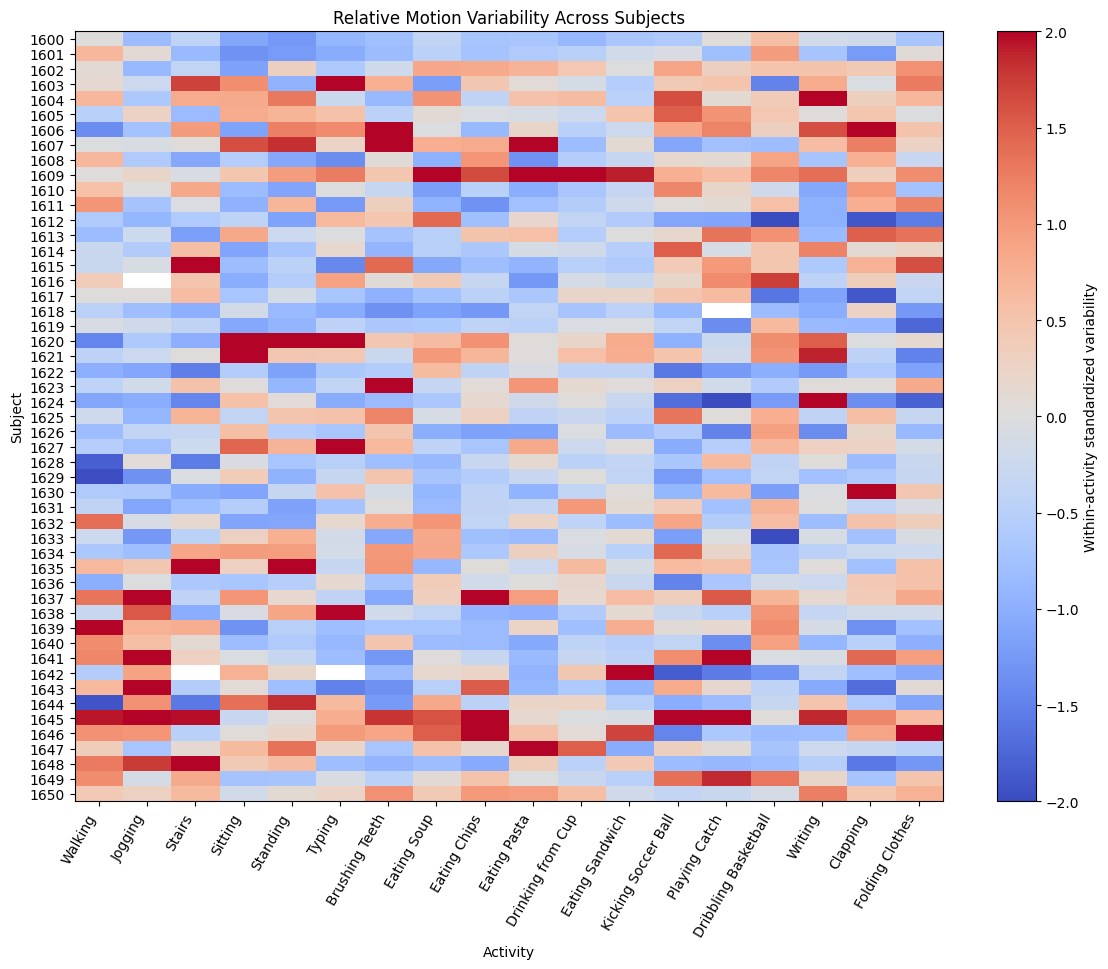

In [111]:
subject_matrix = (
    subject_activity_variability
    .pivot(
        index="subject_id",
        columns="activity",
        values="std_magnitude",
    )
    .reindex(columns=activities)
)

activity_mean = subject_matrix.mean(axis=0)
activity_std = subject_matrix.std(axis=0)

subject_matrix_z = (
    subject_matrix - activity_mean
) / activity_std


fig, ax = plt.subplots(figsize=(14, 10))

image = ax.imshow(
    subject_matrix_z,
    aspect="auto",
    cmap="coolwarm",
    vmin=-2,
    vmax=2,
)

ax.set_xticks(range(len(subject_matrix_z.columns)))
ax.set_xticklabels(
    subject_matrix_z.columns,
    rotation=60,
    ha="right",
)

ax.set_yticks(range(len(subject_matrix_z.index)))
ax.set_yticklabels(subject_matrix_z.index)

ax.set(
    title="Relative Motion Variability Across Subjects",
    xlabel="Activity",
    ylabel="Subject",
)

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Within-activity standardized variability")

plt.show()

The heatmap shows substantial subject-to-subject variation, but the pattern is
not simply that some participants move more strongly during every activity.

Many rows contain a mixture of above- and below-average activities, suggesting a
subject–activity interaction: a participant may perform one activity with
unusually high variability and another with unusually low variability.

Some subjects, including subjects near 1645–1646, show above-average variability
across several activities, while other participants have more isolated
activity-specific deviations. No single consistent subject ordering is visible
across all classes.

The heatmap therefore supports the conclusion that activity signals depend on
the individual performing the activity. However, because phone and watch
accelerometers are combined, part of this structure may also reflect device
placement or modality availability rather than participant behavior alone.

### 10.3 Activities with the greatest relative subject variability

For each activity, we summarize the mean, standard deviation, and median of the
combined subject-level variability measure.

The coefficient of variation is calculated as:

\[
\text{CV} =
\frac{\text{between-subject standard deviation}}
     {\text{between-subject mean}}
\]

This expresses between-subject spread relative to the activity's average motion
variability. It is dimensionless and allows activities with different mean
levels to be compared.

However, CV becomes large when the denominator is small. High-CV low-motion
activities do not necessarily have the largest absolute differences between
subjects.

In [112]:
activity_subject_variation = (
    subject_activity_variability
    .groupby("activity", observed=True)["std_magnitude"]
    .agg(["mean", "std", "median"])
)

activity_subject_variation["coefficient_of_variation"] = (
    activity_subject_variation["std"]
    / activity_subject_variation["mean"]
)

activity_subject_variation = (
    activity_subject_variation
    .reindex(activities)
    .sort_values(
        "coefficient_of_variation",
        ascending=False,
    )
)

activity_subject_variation

,mean,std,median,coefficient_of_variation
activity,,,,
Eating Sandwich,0.425634,0.353480,0.342750,0.830479
Drinking from Cup,0.340047,0.252574,0.289872,0.742763
Standing,0.348869,0.227218,0.292713,0.651298
Sitting,0.339107,0.215605,0.323328,0.635801
Brushing Teeth,0.816924,0.444847,0.721054,0.544539
Typing,0.378932,0.178506,0.353939,0.471077
Eating Pasta,0.428197,0.190311,0.414020,0.444448
Eating Chips,0.430583,0.185409,0.361795,0.430600
Eating Soup,0.366380,0.152390,0.314091,0.415933


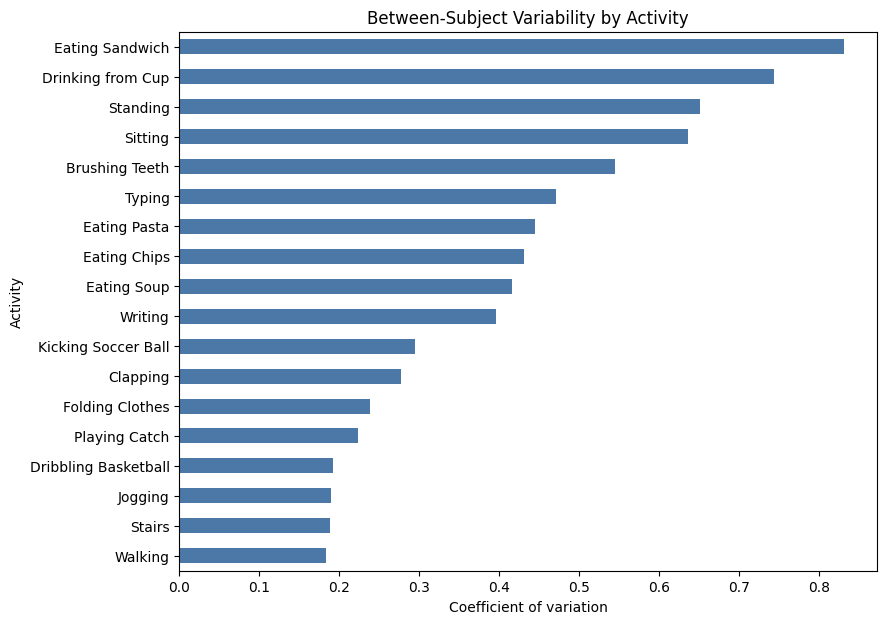

In [113]:
fig, ax = plt.subplots(figsize=(9, 7))

activity_subject_variation[
    "coefficient_of_variation"
].sort_values().plot.barh(
    ax=ax,
    color="#4C78A8",
)

ax.set(
    xlabel="Coefficient of variation",
    ylabel="Activity",
    title="Between-Subject Variability by Activity",
)

plt.show()

Eating Sandwich and Drinking from Cup have the largest coefficients of
variation, approximately 0.83 and 0.74. Standing and Sitting also have relatively
large values, approximately 0.65 and 0.64.

These are mostly low-motion activities with small mean magnitude variability.
Their high ranking indicates that subject differences are large relative to
their low average motion level.

By contrast, Walking, Stairs, Jogging, and Dribbling Basketball have coefficients
of variation near 0.18–0.19. This does not mean that their subjects have little
absolute variation. Jogging, for example, has the largest absolute
between-subject standard deviation in the table, approximately 1.39, but its
mean variability is also high, producing a smaller relative CV.

The CV ranking therefore answers a specific question—relative subject spread—not
overall absolute heterogeneity or expected classification difficulty.
Generalization difficulty must be evaluated directly using held-out subjects and
per-activity model performance.

### 10.4 Subject-variability findings

The same labeled activity can produce meaningfully different motion variability
across subjects. These differences are often activity-specific rather than a
single consistent high- or low-motion tendency for each participant.

Low-motion activities such as Eating Sandwich, Drinking from Cup, Standing, and
Sitting show the greatest variability relative to their mean motion level.
High-motion activities have larger absolute variability in several cases but
smaller relative coefficients of variation.

The current analysis combines phone and watch accelerometers and should therefore
be treated as a broad diagnostic. A device-specific analysis would be required
to distinguish participant variability from placement and modality effects.

These findings reinforce several modeling requirements:

- training and evaluation must be split by subject, never by individual rows or
  windows;
- grouped cross-validation or leave-one-subject-out evaluation should be
  considered;
- results should include per-activity performance, not only overall accuracy;
- performance variation across held-out subjects should also be reported;
- scaling, feature selection, and preprocessing decisions must be learned from
  training subjects only.

No subjects should be removed simply because their motion differs from the
population average. Such variation is part of the generalization problem the
model is expected to solve.

## 11. EDA Findings and Preprocessing/Modeling Decisions

This final section answers:

> What conclusions from the EDA should guide preprocessing, modeling, and evaluation?

The exploratory results identify important properties of the dataset, but they
do not by themselves determine an optimal preprocessing pipeline or classifier.
The decisions below therefore distinguish established findings from choices that
still require validation using training subjects.

### 11.1 Main EDA findings

The cleaned dataset provides broad but imperfect coverage of the intended
activity-recognition problem:

- 51 subjects and all 18 activities are represented;
- four subject/activity combinations are completely absent;
- 35 of the 3,672 possible device–sensor streams are missing;
- most subject/activity pairs nevertheless contain all four streams.

Most streams span approximately three minutes, but the temporal structure is not
uniform. Sampling cadence varies systematically across subjects and devices,
and some streams contain substantial gaps. A fixed number of rows therefore
does not consistently represent a fixed duration.

Accelerometer and gyroscope streams from the same device are generally aligned.
Phone and watch raw timestamps, however, use different clock origins and cannot
be compared or merged directly.

The signal analyses show that:

- locomotion activities usually produce strong magnitude and periodic patterns;
- the watch is especially informative for several hand-oriented activities;
- phone and watch measurements provide complementary information;
- many static and fine-motor activities overlap in simple magnitude summaries;
- frequency estimates are useful for rhythmic motion but can be unreliable for
  weak, static, or irregular signals;
- substantial activity-specific variation exists between subjects.

Consequently, neither raw row counts, a single whole-recording statistic, nor
one dominant-frequency estimate is sufficient to characterize the
classification problem.

### 11.2 Preprocessing requirements

The preprocessing pipeline should preserve the temporal and grouped structure
identified during the EDA.

1. **Preserve identifiers.** Subject, activity, device, sensor, and recording
   identifiers must remain available throughout preprocessing.

2. **Respect subject boundaries.** Subjects must be assigned to training,
   validation, and test groups so that no rows or windows from the same subject
   appear in different partitions.

3. **Construct continuous segments.** Long timestamp gaps should be treated as
   sequence boundaries. Windows must not bridge these interruptions.

4. **Use timestamps rather than row positions.** Streams should be represented
   on a relative-time scale and resampled within continuous segments to a
   justified common frequency.

5. **Handle multimodal alignment explicitly.** Within-device sensor fusion is
   relatively straightforward, but phone–watch fusion requires a separate,
   validated alignment procedure because their raw clock values are not
   directly comparable.

6. **Define a missing-stream policy.** Missing sensor streams should remain
   missing rather than being artificially generated. Each model configuration
   must specify which devices and sensors are required.

7. **Apply window-quality rules.** Final windows should satisfy explicit
   requirements for duration, temporal coverage, sample availability, internal
   gaps, and signal validity. The preliminary five-second bins from Section 8
   are diagnostic and are not yet final model inputs.

8. **Retain complementary representations.** The original axes should be
   preserved, while magnitude may be added as an orientation-reducing feature
   rather than used as a replacement.

9. **Scale channels appropriately.** Accelerometer and gyroscope channels, and
   potentially phone and watch channels, should be scaled separately. All
   scaling parameters must be learned from training subjects only.

10. **Treat extremes cautiously.** Rare extreme measurements should initially
    be retained. Any clipping, robust scaling, or window rejection rule should
    be justified using stream- and window-level diagnostics.

### 11.2 Preprocessing requirements

The preprocessing pipeline should preserve the temporal and grouped structure
identified during the EDA.

1. **Preserve identifiers.** Subject, activity, device, sensor, and recording
   identifiers must remain available throughout preprocessing.

2. **Respect subject boundaries.** Subjects must be assigned to training,
   validation, and test groups so that no rows or windows from the same subject
   appear in different partitions.

3. **Construct continuous segments.** Long timestamp gaps should be treated as
   sequence boundaries. Windows must not bridge these interruptions.

4. **Use timestamps rather than row positions.** Streams should be represented
   on a relative-time scale and resampled within continuous segments to a
   justified common frequency.

5. **Handle multimodal alignment explicitly.** Within-device sensor fusion is
   relatively straightforward, but phone–watch fusion requires a separate,
   validated alignment procedure because their raw clock values are not
   directly comparable.

6. **Define a missing-stream policy.** Missing sensor streams should remain
   missing rather than being artificially generated. Each model configuration
   must specify which devices and sensors are required.

7. **Apply window-quality rules.** Final windows should satisfy explicit
   requirements for duration, temporal coverage, sample availability, internal
   gaps, and signal validity. The preliminary five-second bins from Section 8
   are diagnostic and are not yet final model inputs.

8. **Retain complementary representations.** The original axes should be
   preserved, while magnitude may be added as an orientation-reducing feature
   rather than used as a replacement.

9. **Scale channels appropriately.** Accelerometer and gyroscope channels, and
   potentially phone and watch channels, should be scaled separately. All
   scaling parameters must be learned from training subjects only.

10. **Treat extremes cautiously.** Rare extreme measurements should initially
    be retained. Any clipping, robust scaling, or window rejection rule should
    be justified using stream- and window-level diagnostics.

### 11.3 Modeling and evaluation strategy

A useful modeling progression is to begin with interpretable baselines and add
complexity only when it provides measurable subject-independent improvement.

Possible comparisons include:

- individual device–sensor models;
- phone-only and watch-only sensor fusion;
- combined phone–watch models after validated alignment;
- feature-based classifiers using time- and frequency-domain summaries;
- sequence models using consistently resampled windows.

Time-domain features should describe level, variability, range, and signal
shape. Frequency features should include peak strength or prominence and
band-level information rather than forcing every window to have a meaningful
dominant frequency.

Evaluation must be subject-independent. Grouped cross-validation or
leave-one-subject-out evaluation should be considered, with preprocessing,
feature selection, and hyperparameter tuning performed using training subjects
only.

Performance should be reported using more than overall accuracy. Appropriate
outputs include:

- macro-averaged precision, recall, and F1 score;
- balanced accuracy;
- per-activity metrics and a confusion matrix;
- the distribution of performance across held-out subjects;
- the number of valid windows supporting each activity and model configuration.

Class support should be assessed after the final segmentation, resampling,
windowing, and quality rules are applied. Raw sensor-row counts should not be
used as the primary measure of class balance.

### 11.4 Final conclusion

The dataset is suitable for wearable activity recognition, but its high overall
coverage does not imply uniform temporal structure or complete multimodal
availability. Variable sampling cadence, temporal gaps, incompatible
phone–watch clock origins, missing streams, and subject-specific motion patterns
must all be handled explicitly.

The EDA supports a gap-aware, timestamp-based, subject-independent workflow.
The next stage should therefore build and validate the preprocessing pipeline
before final window counts or model comparisons are reported. In particular,
the resampling frequency, gap threshold, window duration, overlap, quality
criteria, required sensor combination, and phone–watch alignment method remain
model-development choices rather than conclusions established by this EDA.